In [1]:
from vip_hci.fits import open_fits
from hciplot import plot_frames, plot_cubes
import matplotlib.pyplot as plt 
import numpy as np
from vip_hci.fm import normalize_psf
from vip_hci.config import VLT_SPHERE_IRDIS
from vip_hci.psfsub import pca, median_sub
from vip_hci.preproc import frame_crop
from astropy.io import fits
import os
from glob import glob
from vip_hci.fm import firstguess
from vip_hci.metrics import detection, contrast_curve
from vip_hci.config import VLT_SPHERE_IRDIS
from HCIutils import circular_aperture
from vip_hci.var import frame_center
from vip_hci.fm import cube_planet_free

In [2]:
data_cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_processed_data/HD11397/IRDIS/2023-07-24/DB_H23/left/raw_files/left_master_cube_PCA.fits')

# plot_cubes(data_cube, vmin = 0, vmax=1000)

In [3]:
def run_pca(cube, angs, flux):
    imlib =  imlib_rot = 'opencv' # other options: 'opencv', 'skimage'
    interpolation= 'bilinear'  
    svd_mode= 'pytorch'

    plot_frames([flux, cube[0]])
    
    pca_residual = pca(np.nan_to_num(cube), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30, svd_mode=svd_mode)

    cropped_residual = frame_crop(pca_residual, 200)

    plot_frames([pca_residual, cropped_residual])
    plt.show()

    psfn, flux_count, fwhm_IRDIS = normalize_psf(flux, size=15, debug=True, full_output=True)

    starphot = np.nansum(flux)
    psf_model = flux/starphot
    plt.show()
    
    cy,cx = frame_center(pca_residual)

    central_mask = circular_aperture(pca_residual[cy-100:cy+100,cx-100:cx+100 ], 30, inverted = True)
    plot_frames(pca_residual[cy-100:cy+100,cx-100:cx+100 ])
    plt.show()

    catalog = detection(pca_residual[cy-100:cy+100,cx-100:cx+100]*central_mask, fwhm=fwhm_IRDIS, psf=psf_model, debug=False, mode='log', snr_thresh=5, bkg_sigma=5, matched_filter=False, mask = True)

    xy_test = (catalog[1][0],catalog[0][0])

    r_lo, theta_lo, f_lo = firstguess(cube[:,cy-100:cy+100,cx-100:cx+100], angs, psf_model, ncomp=5, planets_xy_coord=[xy_test], 
                                fwhm=fwhm_IRDIS, f_range=None, annulus_width=4*fwhm_IRDIS, 
                                aperture_radius=2, simplex=True, imlib=imlib_rot, svd_mode=svd_mode, 
                                interpolation=interpolation, plot=True, verbose=True)
    

    ratio = f_lo/starphot 
    delta_mag = - 2.5 * np.log10(ratio)

    mag =  7.318 + delta_mag

    parallax = 18.4075 * 10-3 #arcssec


    d = 1/parallax #distance in pc
    mu = 5*np.log10(d/10) #distance modulus
    abs_mag = mag - mu

    print(abs_mag, mag, delta_mag, ratio)

    plpar_fc = (r_lo[0], theta_lo[0], f_lo[0])

    cube_emp = cube_planet_free(plpar_fc, cube, angs, psf_model, imlib=imlib_rot, interpolation=interpolation)

    pca_residual_free = pca(np.nan_to_num(cube_emp[:,300:-300,300:-300]), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30)


    cropped_residual_free = frame_crop(pca_residual_free, 200)

    plot_frames([cropped_residual, cropped_residual_free])

    pxscale = VLT_SPHERE_IRDIS['plsc']

    cc_1 = contrast_curve(cube_emp[:,300:-300,300:-300], angs, psf_model, fwhm=fwhm_IRDIS, pxscale=pxscale, starphot=starphot, fc_rad_sep = 12, fc_snr = 8,
                       sigma=5, nbranch=1, algo=pca, ncomp=5, nproc=30, debug=True, svd_mode=svd_mode, verbose=True, interpolation ='bilinear', imlib='opencv')
    
    return abs_mag, mag, delta_mag, ratio


#run_pca(cube[:,200:-200,200:-200], angs, flux)

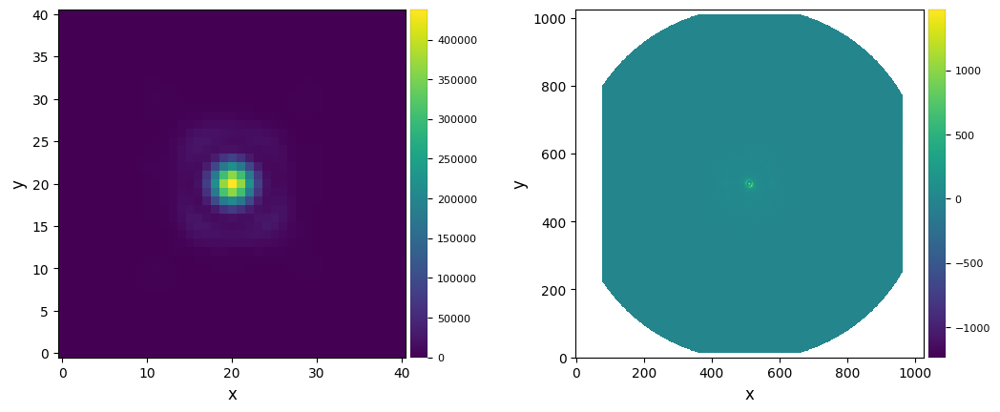

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-06-24 14:38:56
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 716.435 GB
Done vectorizing the frames. Matrix shape: (524, 1050625)
Done SVD/PCA with pytorch (GPU)
Running time:  0:00:09.993142
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:01:45.698115
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


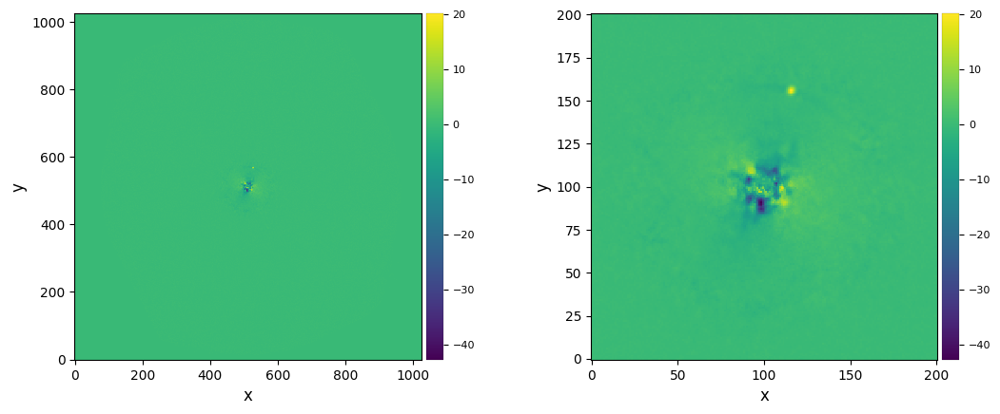

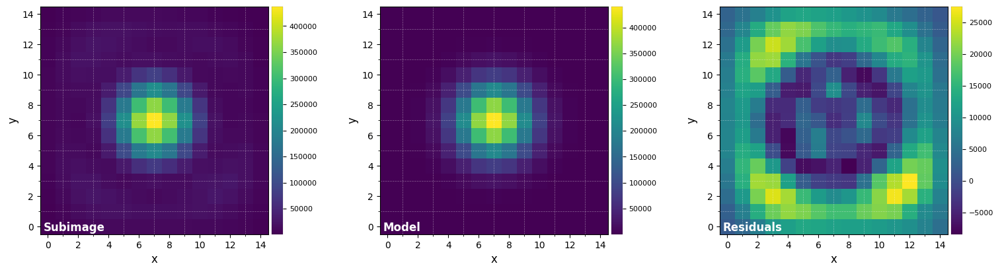

FWHM_y = 3.835989509667941
FWHM_x = 3.898395158440269 

centroid y = 6.999978990094858
centroid x = 7.000021831992548
centroid y subim = 6.999978990094858
centroid x subim = 7.000021831992548 

amplitude = 441054.5579492928
theta = -1.616506297310774

Mean FWHM: 3.867
Flux in 1xFWHM aperture: 3650406.264


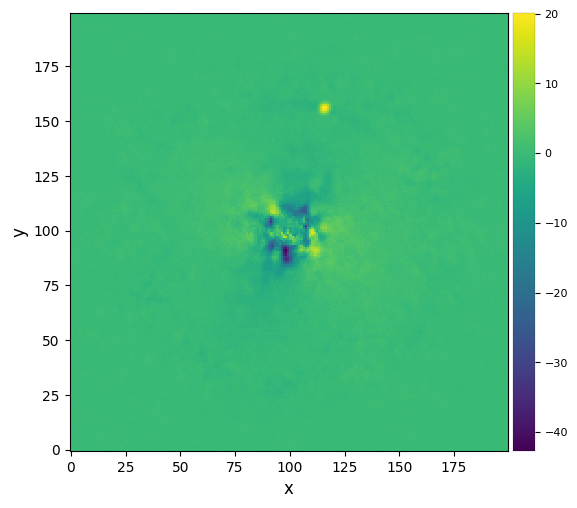

Blobs found: 1
 ycen   xcen
------ ------
155.676 	 115.567

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (115.6,155.7)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 115.6, 155.7
Flux in a centered 1xFWHM circular aperture = 172.460
Central pixel S/N = 22.041
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 16.302
Max S/N (shifting the aperture center) = 20.777
stddev S/N (shifting the aperture center) = 3.232

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


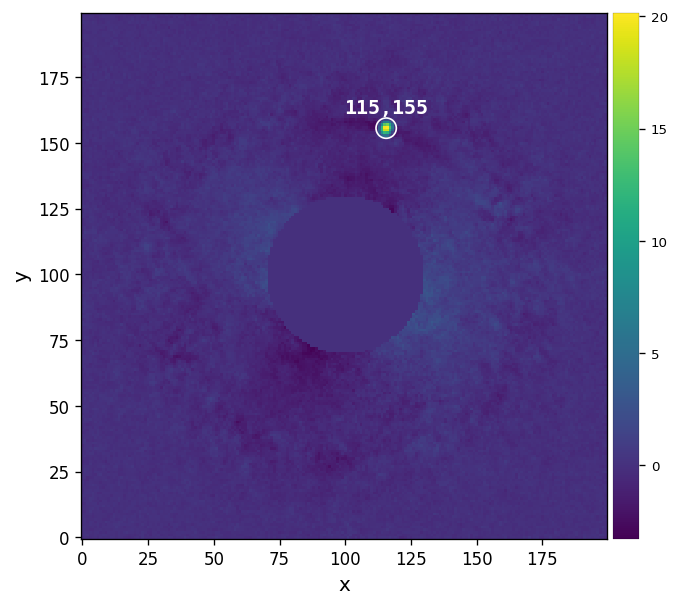

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-06-24 14:40:43
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [115.56717233789574,155.67616127253905], running ...
Step | flux    | chi2r
1/30   0.100   12.820
2/30   0.149   12.819
3/30   0.221   12.817
4/30   0.329   12.814
5/30   0.489   12.808
6/30   0.728   12.801
7/30   1.083   12.789
8/30   1.610   12.772
9/30   2.395   12.746
10/30   3.562   12.708
11/30   5.298   12.653
12/30   7.880   12.571
13/30   11.721   12.447
14/30   17.433   12.271
15/30   25.929   12.028
16/30   38.566   11.628
17/30   57.362   11.089
18/30   85.317   10.259
19/30   126.896   9.087
20/30   188.739   7.424
21/30   280.722   5.274
22/30

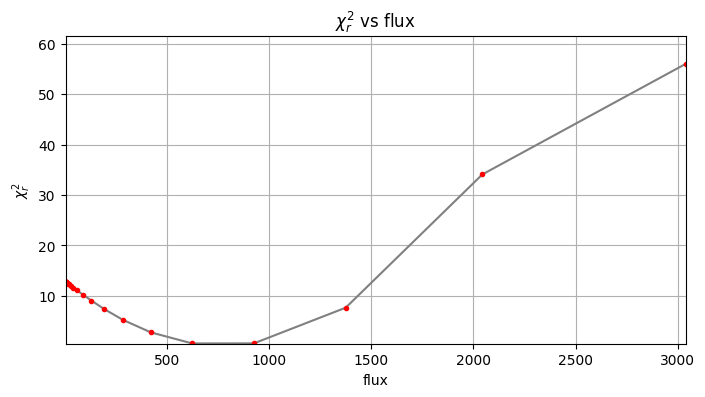

Planet 0: preliminary position guess: (r, theta)=(57.8, 74.4)
Planet 0: preliminary flux guess: 621.0
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 95, nfev: 215, chi2r: 0.09557783505696368
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(57.783, 74.432, 768.487) at 
          (X,Y)=(115.51, 155.66)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:07:26.167682
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
[33.9227313] [17.63343883] [10.31543883] [7.47867165e-05]
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-06-24 14:48:15
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 716.627 GB
Done vector

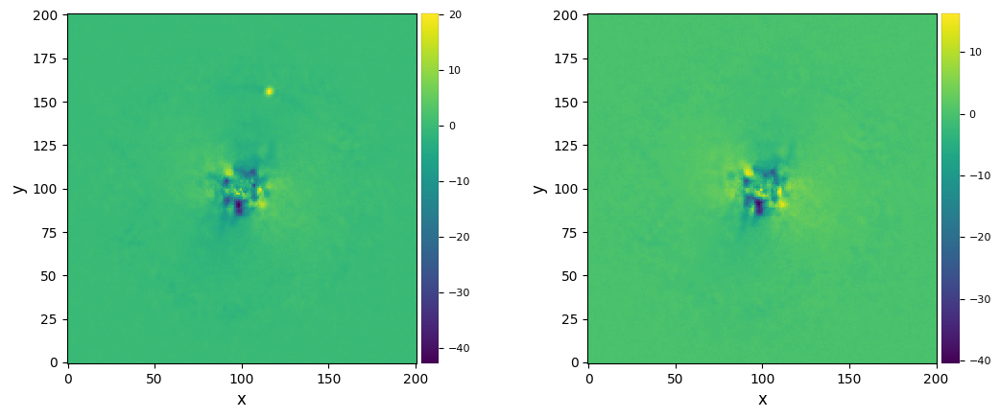

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-06-24 14:48:37
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 3.867192334054105, # BRANCHES = 1, SIGMA = 5, STARPHOT = 10275712.38548537
Finished the throughput calculation
Running time:  0:34:18.230105
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


(array([33.9227313]),
 array([17.63343883]),
 array([10.31543883]),
 array([7.47867165e-05]))

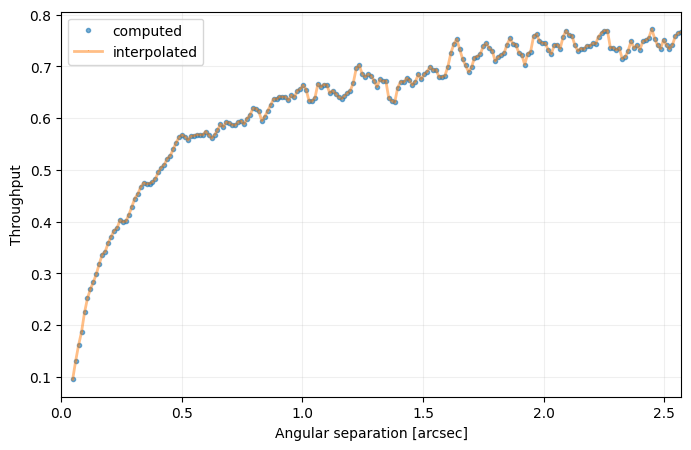

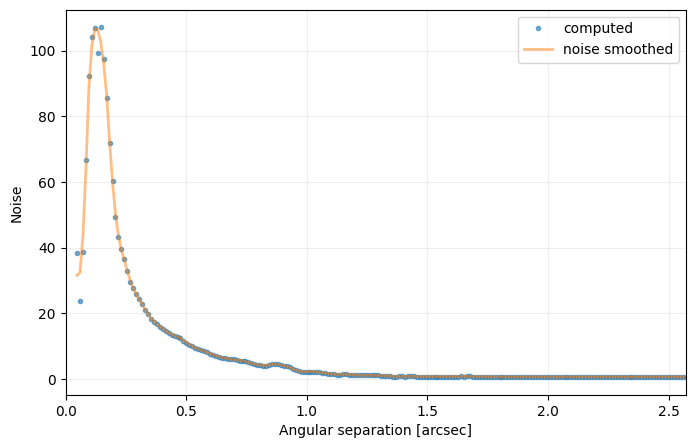

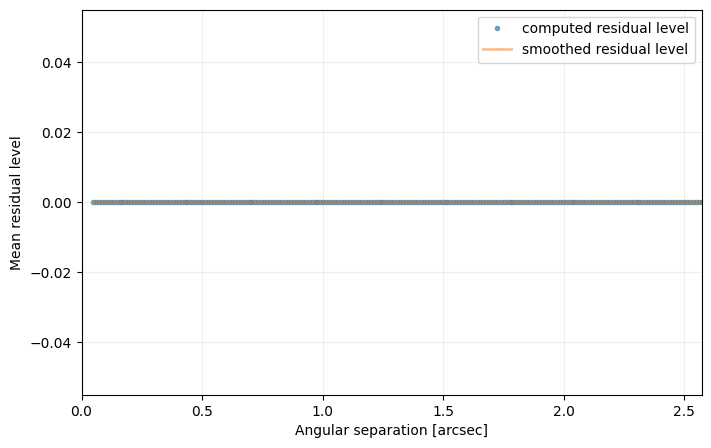

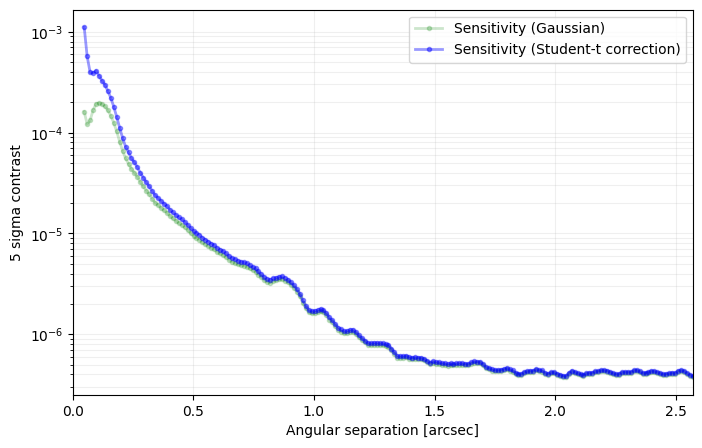

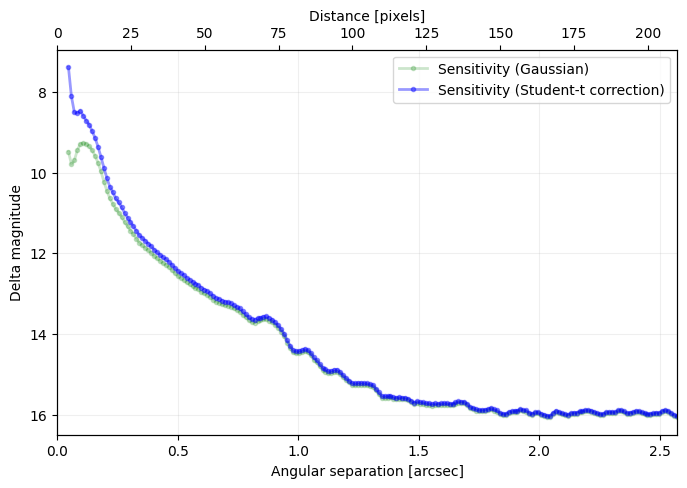

In [4]:
angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_processed_data/HD11397/IRDIS/2023-07-24/DB_H23/left/raw_files/left_parallactic_angles.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_processed_data/HD11397/IRDIS/2023-07-24/DB_H23/left/raw_files/left_master_cube_PCA.fits')
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_processed_data/HD11397/IRDIS/2023-07-24/DB_H23/left/raw_files/FLUX_LEFT_CUT_OUT_SPHER.2023-07-24T07:42:57.613.fits')

run_pca(cube, angs, flux)

In [ ]:
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_processed_data/HD11397/IRDIS/2023-07-24/DB_H23/left/raw_files/FLUX_LEFT_CUT_OUT_SPHER.2023-07-24T07:42:57.613.fits')

ratio = 775.877 / np.nansum(flux)
delta_mag = - 2.5 * np.log10(ratio)

star_mag = 7.318
mag = star_mag  + delta_mag

parallax = 18.4075e-3 #arcssec

d = 1/parallax #distance in pc

mu = 5*np.log10(d/10) #distance modulus
abs_mag = mag - mu

print(abs_mag, mag, delta_mag, ratio, parallax, d ,star_mag)


import pandas as pd 
DF = pd.DataFrame({'abs_mag': [abs_mag], 'mag':[mag], 'delta_mag':[delta_mag], 'flux_ratio':[ratio], 'parallax':[parallax], 'star_mag':[star_mag]})
DF.to_csv('/home/pasteimle/code/hd11397/Own/mag.csv')

13.948021700960988 17.62304765521729 10.305047655217292 7.55059085826439e-05 0.0184075 54.325682466385985 7.318


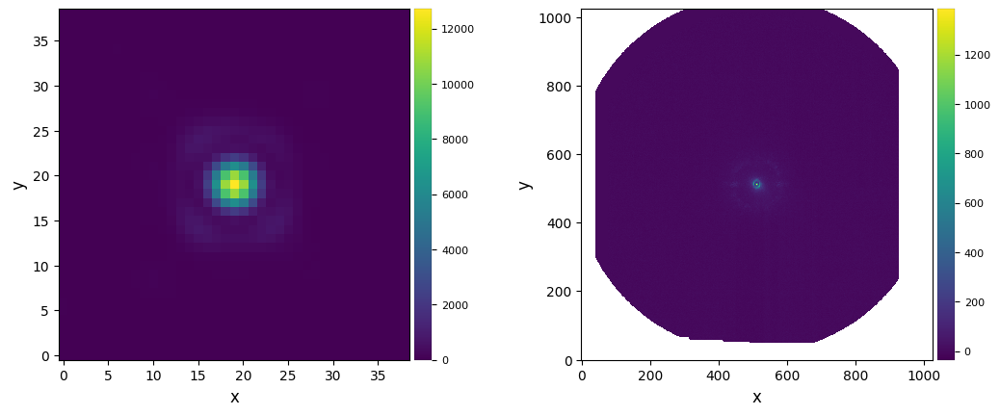

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-06 17:24:09
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 1053.982 GB
Done vectorizing the frames. Matrix shape: (524, 1048576)
Done SVD/PCA with pytorch (GPU)
Running time:  0:00:10.164195
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:02:41.491212
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
New shape: (200, 200)


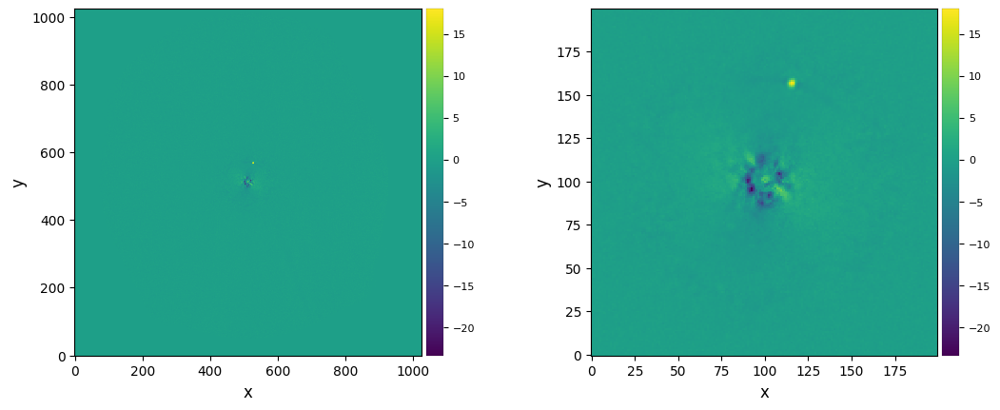

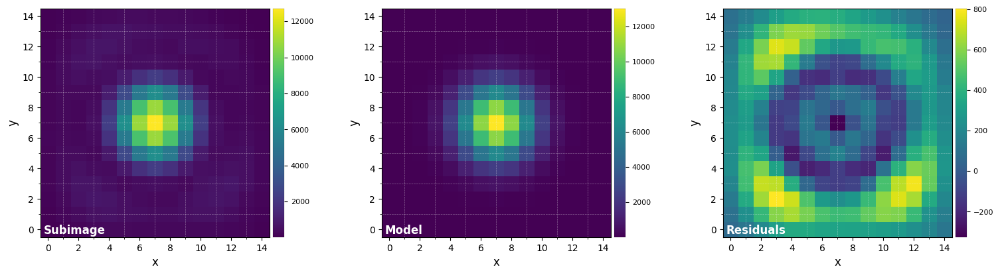

FWHM_y = 3.834513612227397
FWHM_x = 3.8702263425876247 

centroid y = 7.001804490258942
centroid x = 6.998709326891411
centroid y subim = 7.001804490258942
centroid x subim = 6.998709326891411 

amplitude = 13034.889422742417
theta = -13.05165807597504

Mean FWHM: 3.852
Flux in 1xFWHM aperture: 107156.480


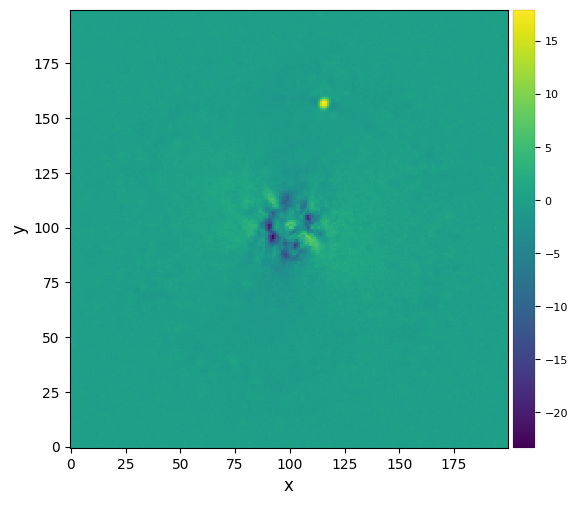

Blobs found: 1
 ycen   xcen
------ ------
156.568 	 115.266

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (115.3,156.6)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 115.3, 156.6
Flux in a centered 1xFWHM circular aperture = 151.518
Central pixel S/N = 30.392
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 22.344
Max S/N (shifting the aperture center) = 29.600
stddev S/N (shifting the aperture center) = 5.411

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


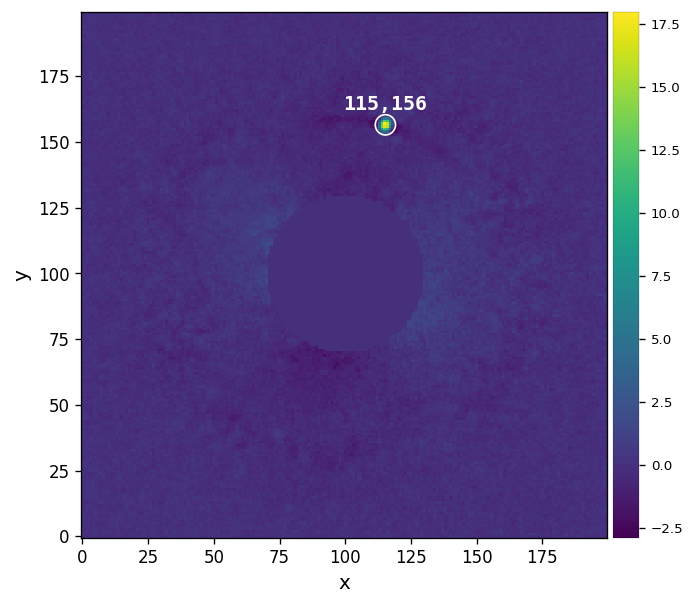

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-06 17:26:53
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [115.2658054874913,156.56790230971455], running ...
Step | flux    | chi2r
1/30   0.100   17.218
2/30   0.149   17.218
3/30   0.221   17.215
4/30   0.329   17.211
5/30   0.489   17.206
6/30   0.728   17.197
7/30   1.083   17.187
8/30   1.610   17.170
9/30   2.395   17.144
10/30   3.562   17.106
11/30   5.298   17.048
12/30   7.880   16.956
13/30   11.721   16.823
14/30   17.433   16.623
15/30   25.929   16.298
16/30   38.566   15.881
17/30   57.362   15.190
18/30   85.317   14.215
19/30   126.896   12.883
20/30   188.739   11.038
21/30   280.722   8.405
22/3

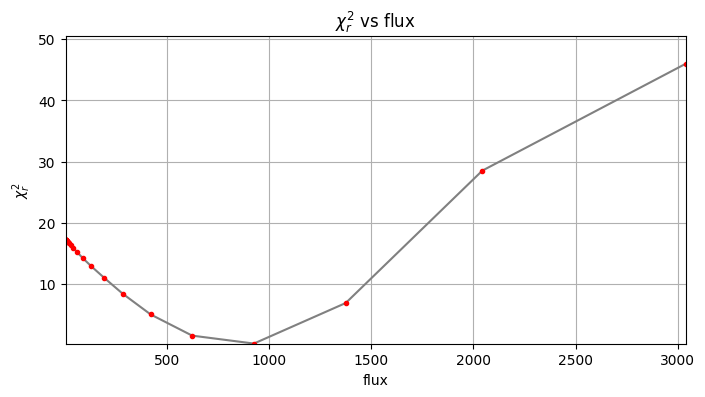

Planet 0: preliminary position guess: (r, theta)=(58.6, 74.9)
Planet 0: preliminary flux guess: 923.7
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 73, nfev: 191, chi2r: 0.10994463740788188
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(58.529, 74.863, 855.656) at 
          (X,Y)=(115.28, 156.50)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:06:33.620138
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
[29.96780014] [13.67850767] [6.36050767] [0.00285625]
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-06 17:33:32
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 1052.854 GB
Done vectorizi

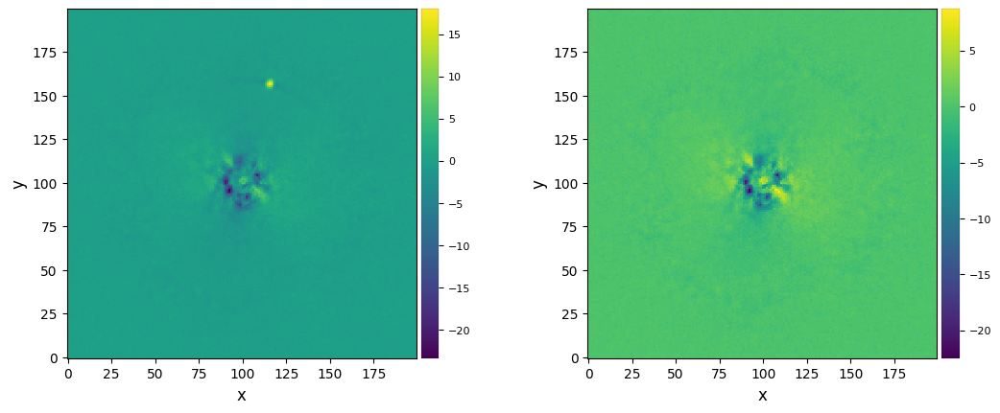

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-06 17:33:53
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 3.852369977407511, # BRANCHES = 1, SIGMA = 5, STARPHOT = 299572.56449733186
Finished the throughput calculation
Running time:  0:18:40.308738
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


(array([29.96780014]),
 array([13.67850767]),
 array([6.36050767]),
 array([0.00285625]))

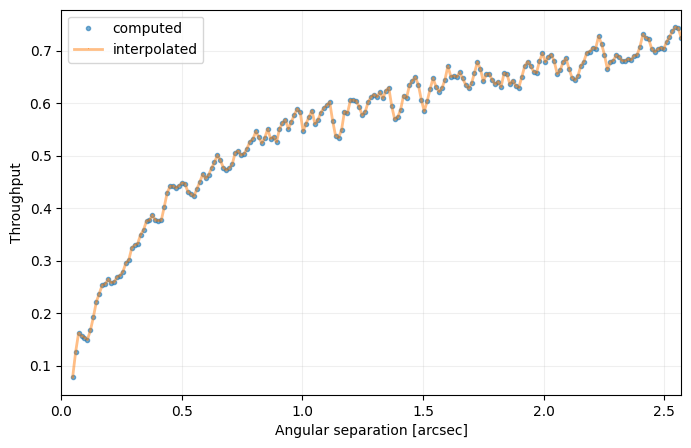

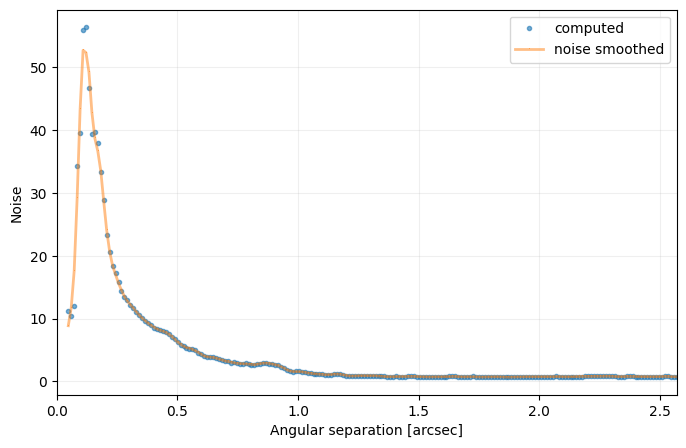

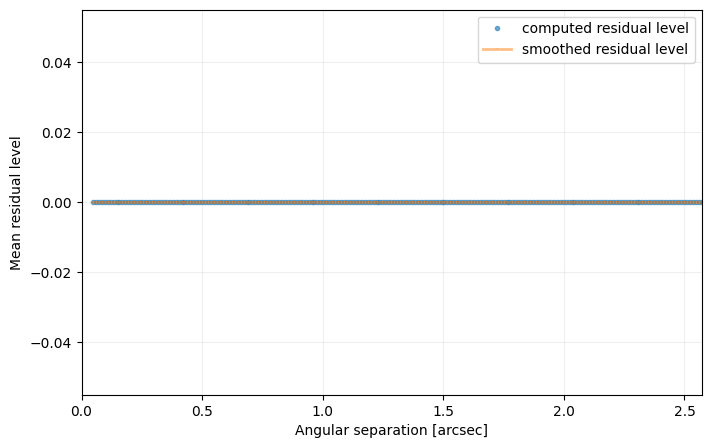

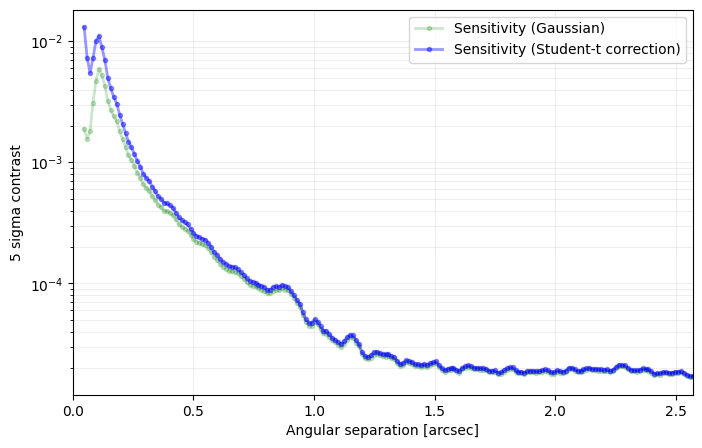

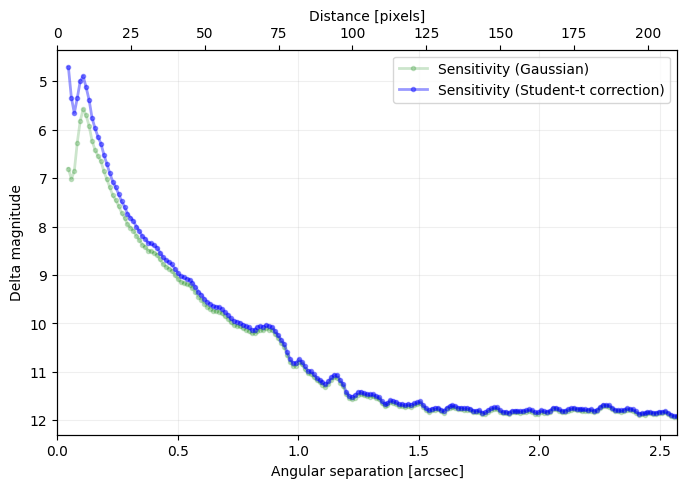

In [ ]:
angs_liz = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_right_parang.txt')
cube_liz = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_left_scicube.fits')
flux_liz = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_left_fluxcube.fits')[1:,1:]

run_pca(cube_liz, angs_liz, flux_liz)

In [ ]:
flux_liz = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_left_fluxcube.fits')


ratio =  855.923 / np.nansum(flux_liz)
delta_mag = - 2.5 * np.log10(ratio)

star_mag = 7.318
mag = star_mag  + delta_mag

parallax = 18.4075e-3 #arcssec

d = 1/parallax #distance in pc

mu = 5*np.log10(d/10) #distance modulus
abs_mag = mag - mu

print(abs_mag, mag, delta_mag, ratio, parallax, d ,star_mag)


import pandas as pd 
DF = pd.DataFrame({'abs_mag': [abs_mag], 'mag':[mag], 'delta_mag':[delta_mag], 'flux_ratio':[ratio], 'parallax':[parallax], 'star_mag':[star_mag]})
DF.to_csv('/home/pasteimle/code/hd11397/Own/mag.csv')


10.005825155229905 13.680851109486209 6.36285110948621 0.002850096443477601 0.0184075 54.325682466385985 7.318


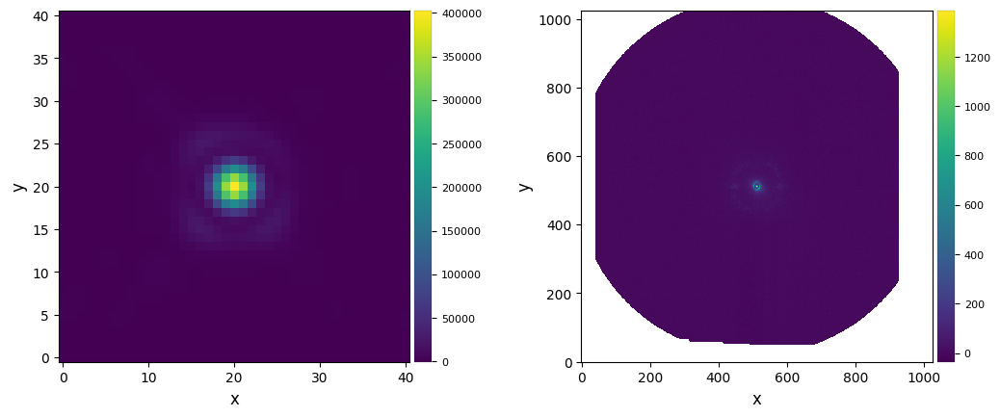

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 13:38:37
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 374.582 GB
Done vectorizing the frames. Matrix shape: (524, 1048576)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:01:22.694189
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:04:08.794255
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
New shape: (200, 200)


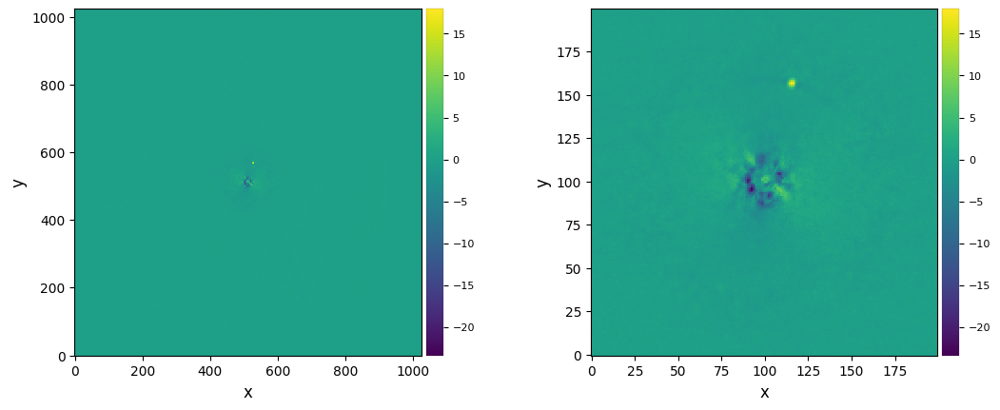

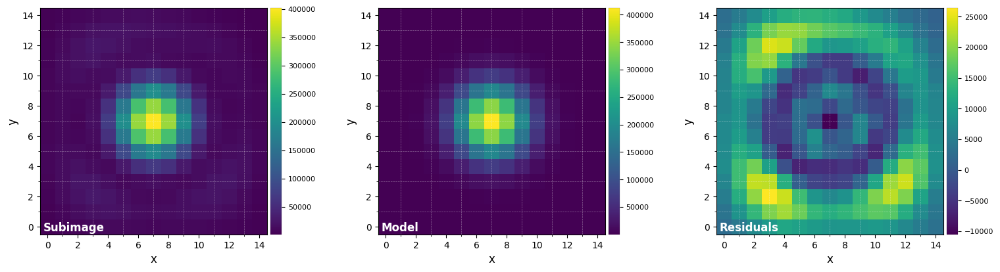

FWHM_y = 3.803968902233996
FWHM_x = 3.838711588240435 

centroid y = 7.000026606907705
centroid x = 6.9999771986827515
centroid y subim = 7.000026606907705
centroid x subim = 6.9999771986827515 

amplitude = 412562.12877426227
theta = -4.888927838077716

Mean FWHM: 3.821
Flux in 1xFWHM aperture: 3337792.815


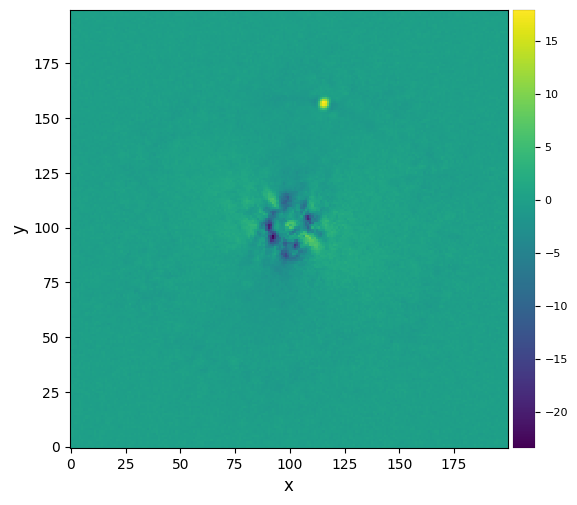

Blobs found: 1
 ycen   xcen
------ ------
156.568 	 115.266

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (115.3,156.6)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 115.3, 156.6
Flux in a centered 1xFWHM circular aperture = 149.773
Central pixel S/N = 30.157
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 23.062
Max S/N (shifting the aperture center) = 30.420
stddev S/N (shifting the aperture center) = 4.994

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


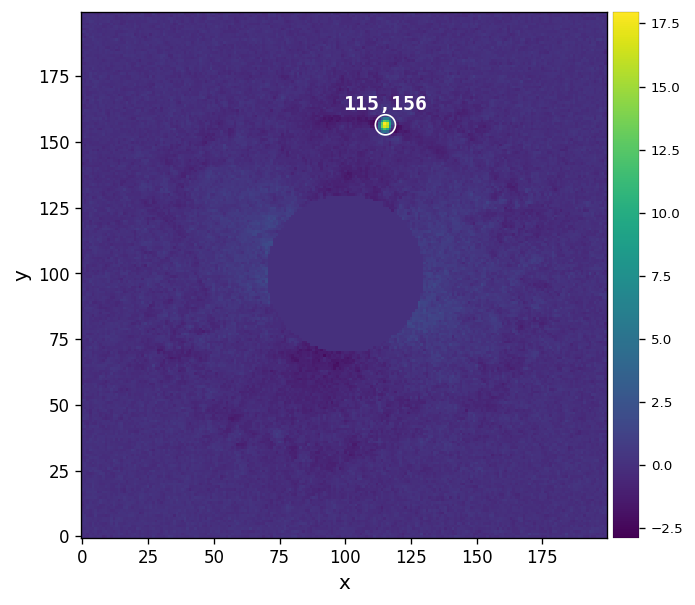

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 13:42:48
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [115.26578282661478,156.56789432946104], running ...
Step | flux    | chi2r
1/30   0.100   17.907
2/30   0.149   17.902
3/30   0.221   17.895
4/30   0.329   17.884
5/30   0.489   17.869
6/30   0.728   17.847
7/30   1.083   17.813
8/30   1.610   17.760
9/30   2.395   17.679
10/30   3.562   17.557
11/30   5.298   17.384
12/30   7.880   17.098
13/30   11.721   16.697
14/30   17.433   16.123
15/30   25.929   15.229
16/30   38.566   13.984
17/30   57.362   12.234
18/30   85.317   9.888
19/30   126.896   6.622
20/30   188.739   2.909
21/30   280.722   0.232
22/30 

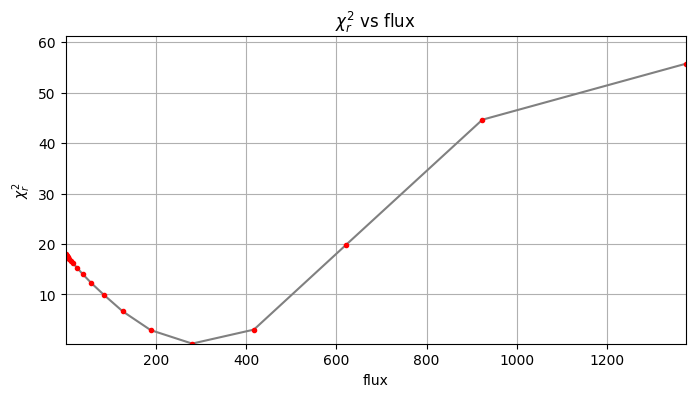

Planet 0: preliminary position guess: (r, theta)=(58.6, 74.9)
Planet 0: preliminary flux guess: 280.7
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 80, nfev: 181, chi2r: 0.11975349543382481
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(58.533, 74.866, 300.161) at 
          (X,Y)=(115.28, 156.50)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:07:03.019755
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 13:49:57
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 373.862 GB
Done vectorizing the frames. Matrix shape: (524, 179776)
Done SVD/PCA

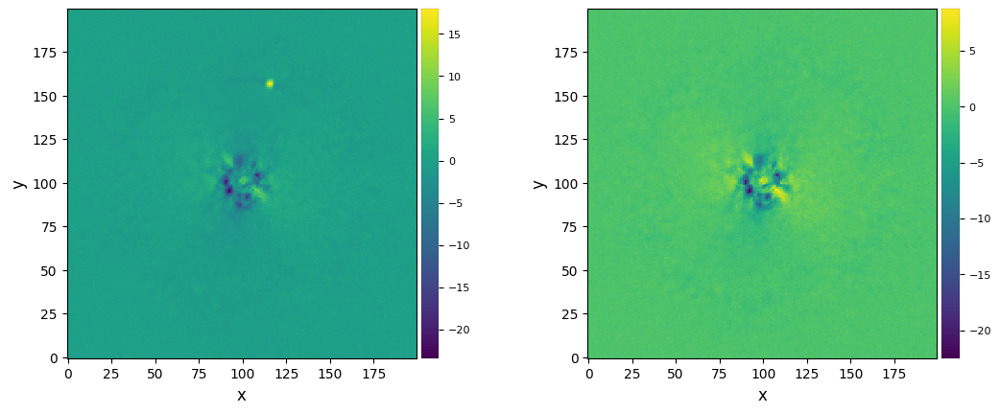

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 13:50:17
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 3.8213402452372156, # BRANCHES = 1, SIGMA = 5
Finished the throughput calculation
Running time:  0:20:27.378491
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


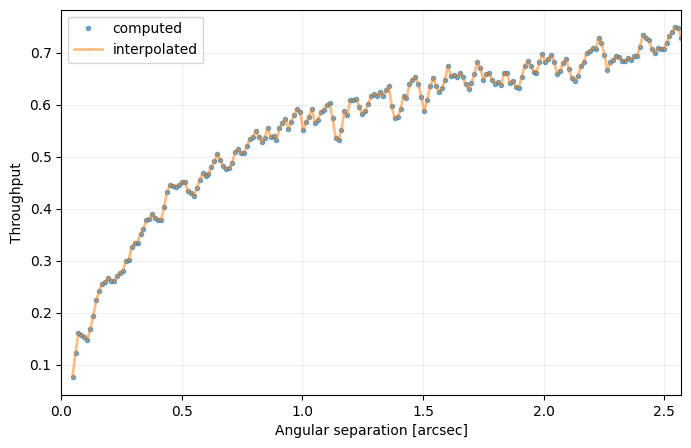

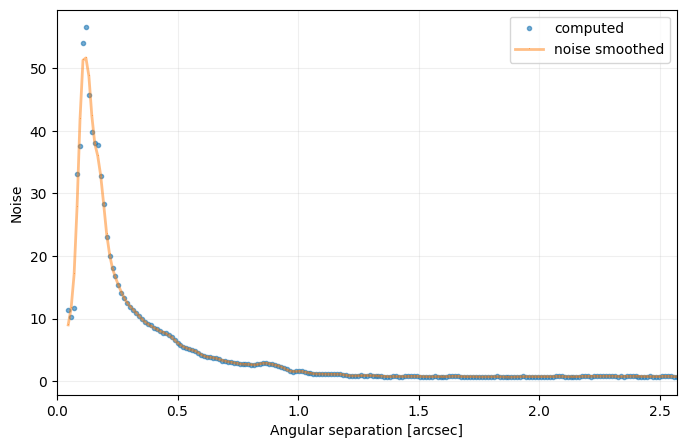

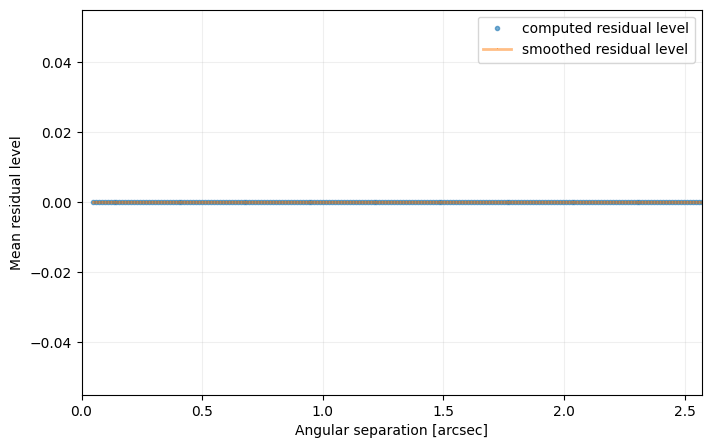

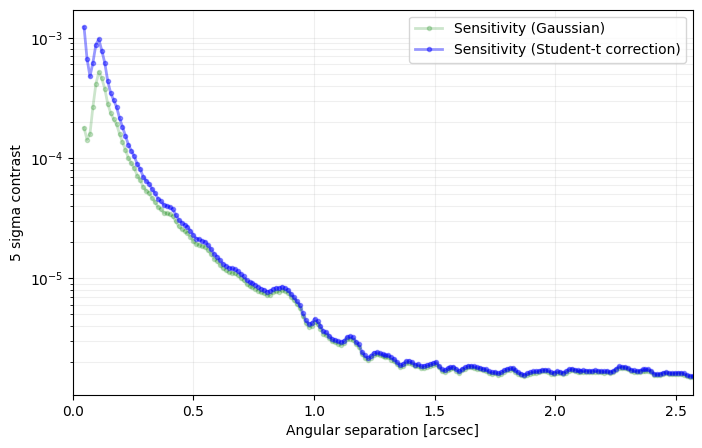

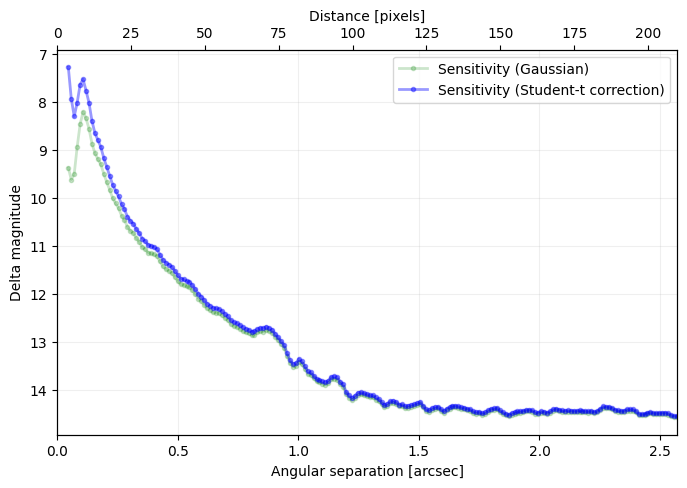

In [ ]:
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction/stage2/2FLUX_LEFT_CUT_OUT_SPHER.2023-07-24T09:55:27.364.fits')
angs_liz = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_right_parang.txt')
cube_liz = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_left_scicube.fits')

run_pca(cube_liz, angs_liz, flux)

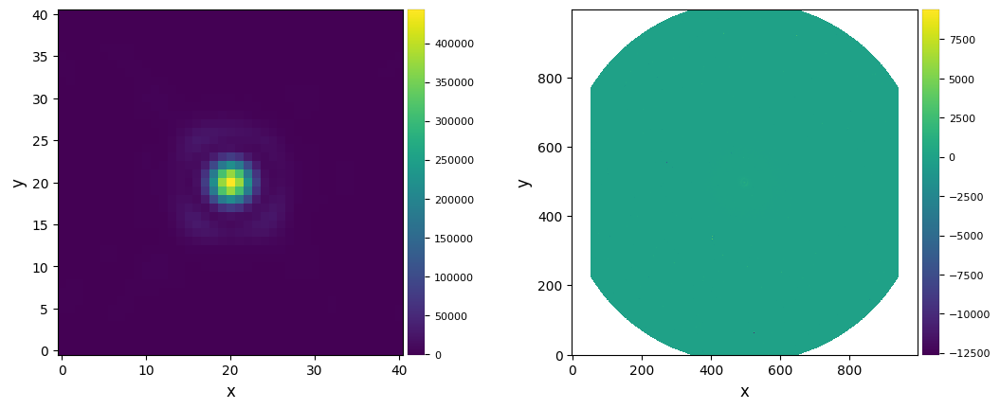

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 17:00:05
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 1001.946 GB
Done vectorizing the frames. Matrix shape: (524, 990025)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:51.000420
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:01:57.613361
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


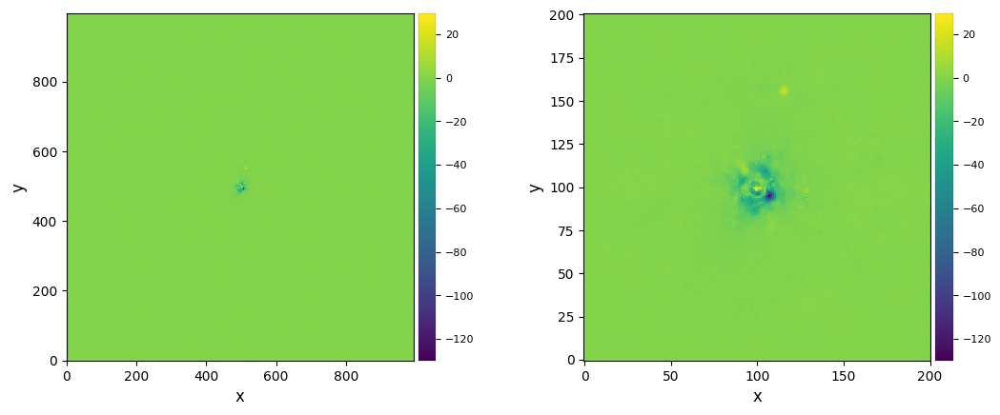

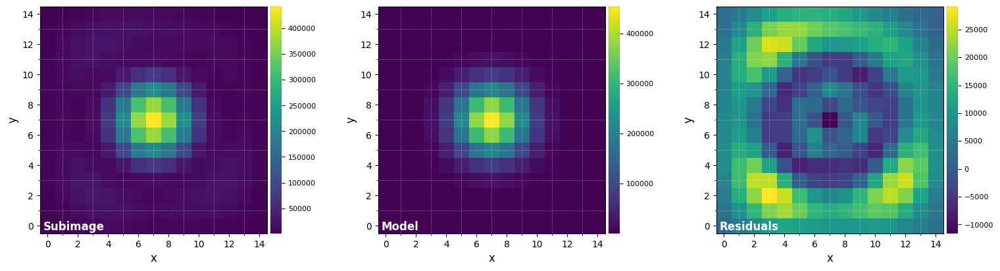

FWHM_y = 3.803968902262489
FWHM_x = 3.8387115882560905 

centroid y = 7.000026565736969
centroid x = 6.9999772207071675
centroid y subim = 7.000026565736969
centroid x subim = 6.9999772207071675 

amplitude = 454306.71144497045
theta = -4.888927841353295

Mean FWHM: 3.821
Flux in 1xFWHM aperture: 3675523.203


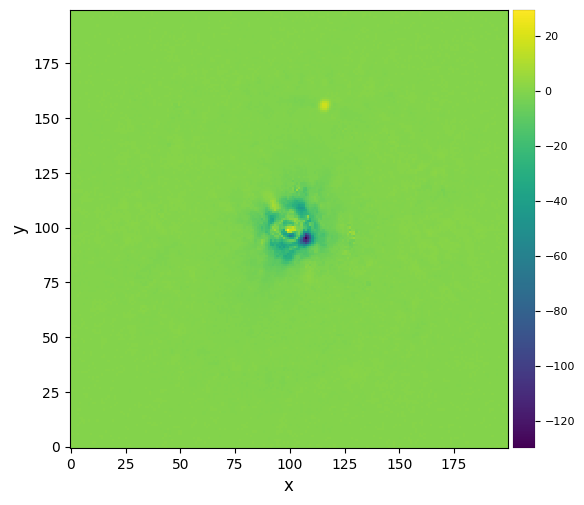

Blobs found: 1
 ycen   xcen
------ ------
155.617 	 115.521

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (115.5,155.6)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 115.5, 155.6
Flux in a centered 1xFWHM circular aperture = 151.950
Central pixel S/N = 25.940
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 19.337
Max S/N (shifting the aperture center) = 24.192
stddev S/N (shifting the aperture center) = 4.013

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


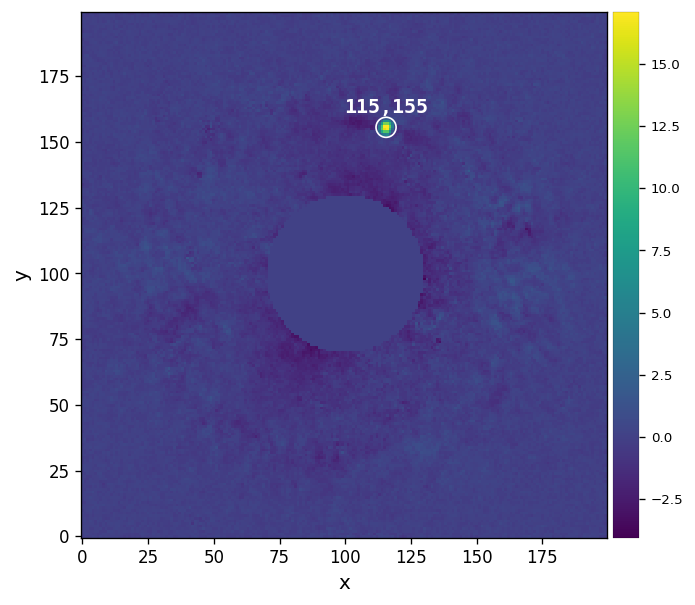

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 17:02:05
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [115.52091343187801,155.61696532509694], running ...
Step | flux    | chi2r
1/30   0.100   11.100
2/30   0.149   11.096
3/30   0.221   11.090
4/30   0.329   11.082
5/30   0.489   11.069
6/30   0.728   11.050
7/30   1.083   11.022
8/30   1.610   10.978
9/30   2.395   10.912
10/30   3.562   10.812
11/30   5.298   10.668
12/30   7.880   10.444
13/30   11.721   10.143
14/30   17.433   9.706
15/30   25.929   9.062
16/30   38.566   8.114
17/30   57.362   6.785
18/30   85.317   5.070
19/30   126.896   2.996
20/30   188.739   0.970
21/30   280.722   0.163
22/30   41

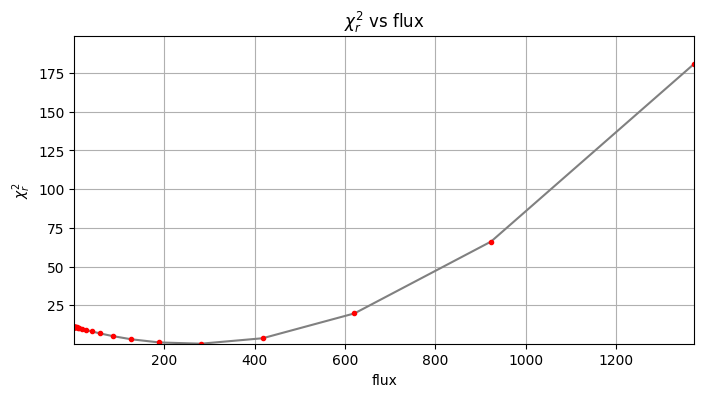

Planet 0: preliminary position guess: (r, theta)=(57.7, 74.4)
Planet 0: preliminary flux guess: 280.7
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 124, nfev: 263, chi2r: 0.10819553110953578
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(57.757, 74.441, 262.656) at 
          (X,Y)=(115.49, 155.64)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:09:26.050523
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 17:11:36
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 1006.431 GB
Done vectorizing the frames. Matrix shape: (524, 156025)
Done SVD/P

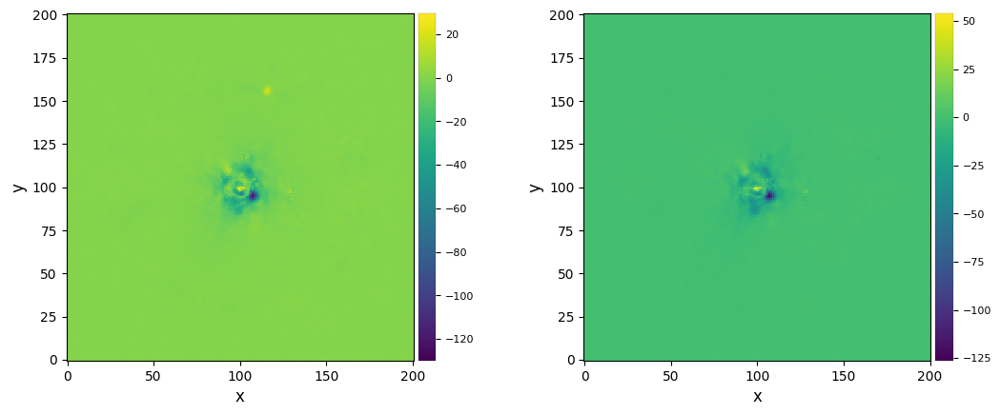

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 17:11:55
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 3.8213402452592895, # BRANCHES = 1, SIGMA = 5
Finished the throughput calculation
Running time:  0:04:25.430514
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


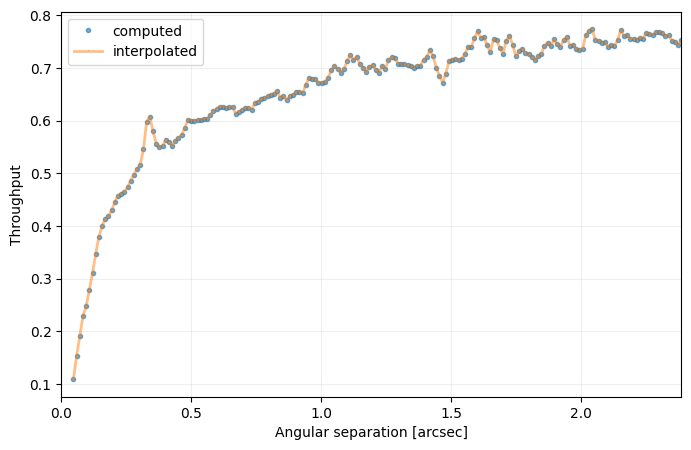

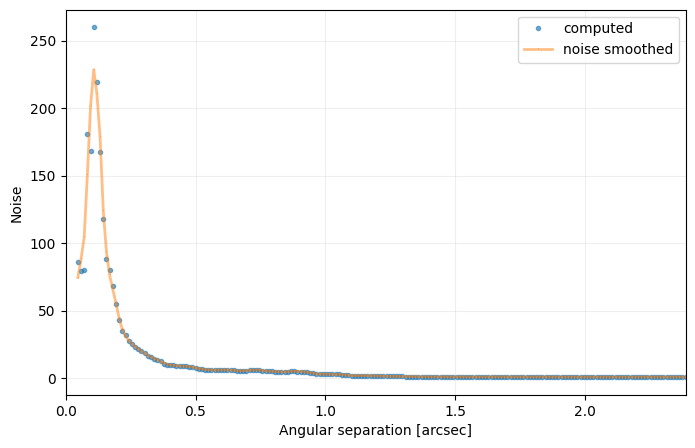

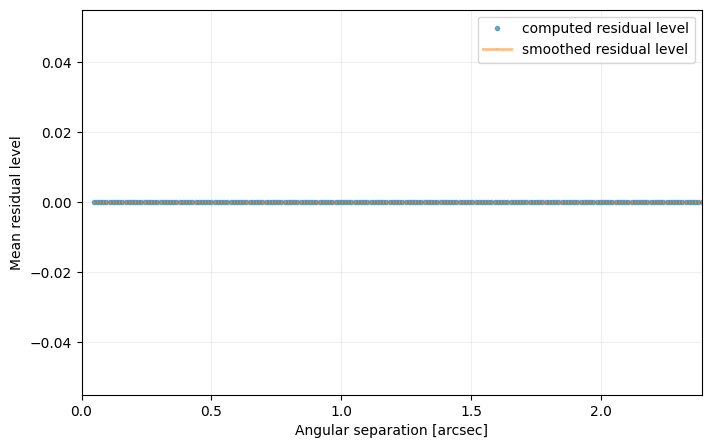

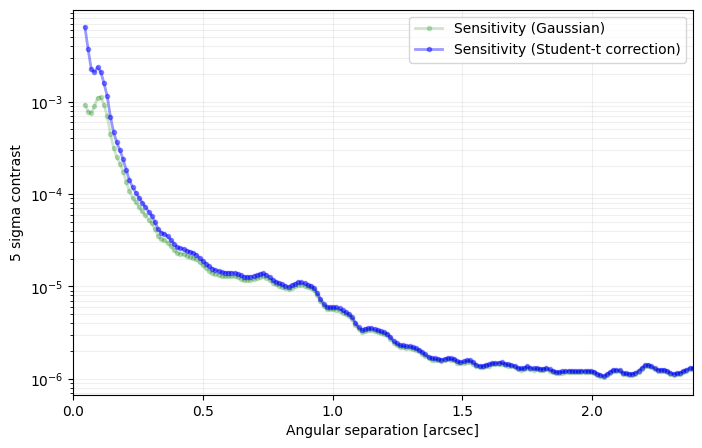

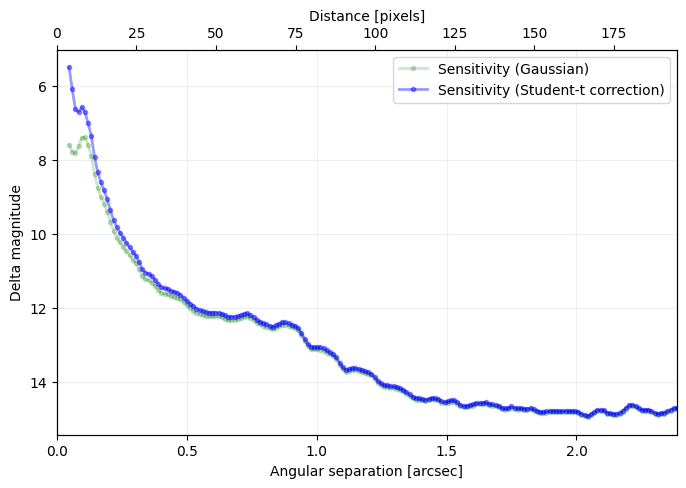

In [ ]:
angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction_2/stage3/left_parallactic_angles.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction_2/stage3/left_mastercube.fits')
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction_2/stage3/FLUX_LEFT_CUT_OUT_SPHER.2023-07-24T09:55:27.364.fits')

run_pca(cube, angs, flux)

(288, 995, 995)


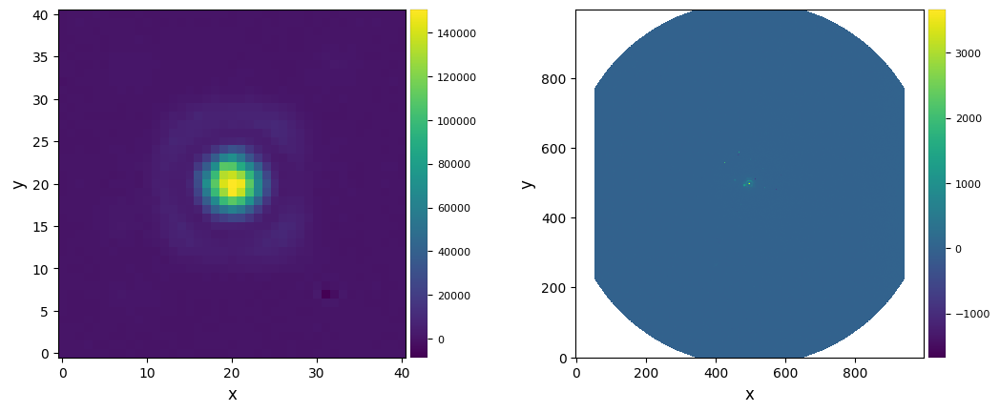

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 10:21:31
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 377.968 GB
Done vectorizing the frames. Matrix shape: (288, 990025)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:37.901106
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:01:14.124930
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


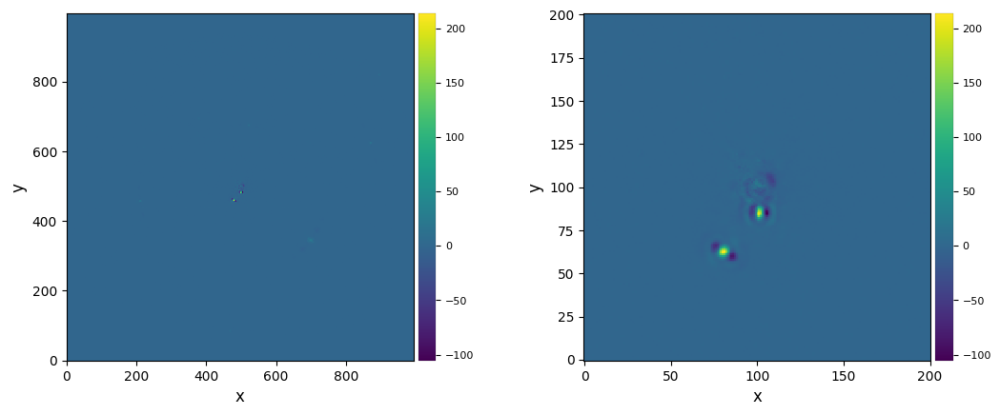

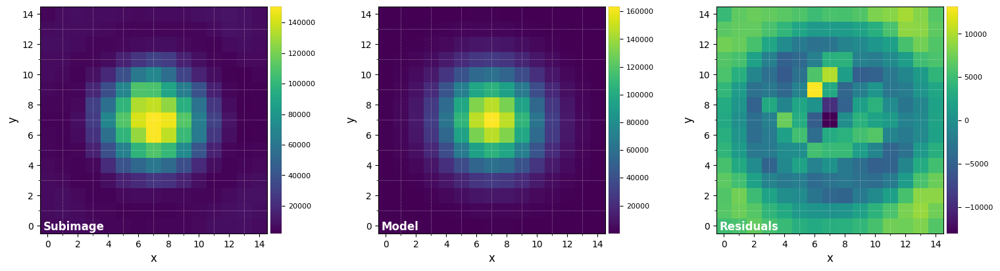

FWHM_y = 4.962046394211901
FWHM_x = 5.159382576572779 

centroid y = 6.999907983173395
centroid x = 7.000140103104112
centroid y subim = 6.999907983173395
centroid x subim = 7.000140103104112 

amplitude = 163501.31331301475
theta = -31.43357967644856

Mean FWHM: 5.061
Flux in 1xFWHM aperture: 2370410.576


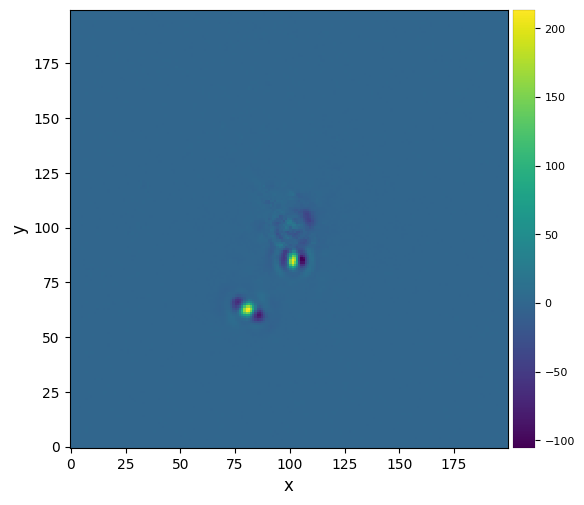

Blobs found: 1
 ycen   xcen
------ ------
62.628 	 80.396

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (80.4,62.6)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 80.4, 62.6
Flux in a centered 1xFWHM circular aperture = 2874.448
Central pixel S/N = 17.321
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 20.131
Max S/N (shifting the aperture center) = 45.267
stddev S/N (shifting the aperture center) = 9.934

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


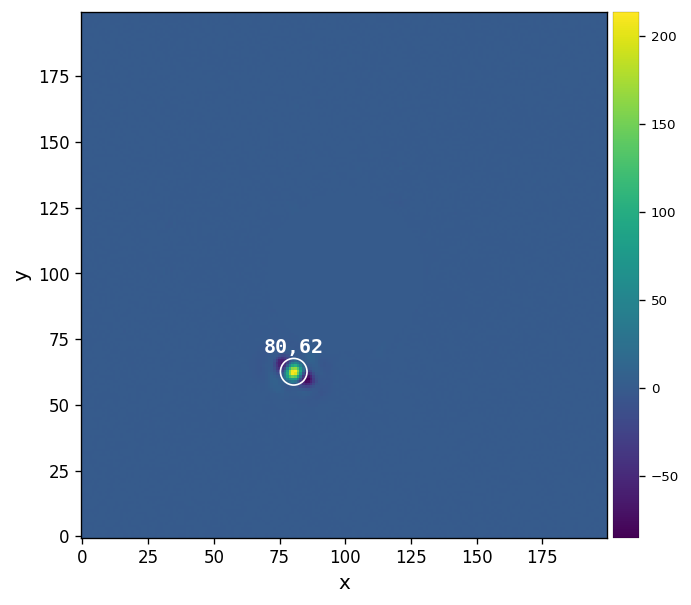

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 10:22:47
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [80.39609384671475,62.627975148058766], running ...
Step | flux    | chi2r
1/30   0.100   42.303
2/30   0.149   42.303
3/30   0.221   42.302
4/30   0.329   42.301
5/30   0.489   42.299
6/30   0.728   42.297
7/30   1.083   42.293
8/30   1.610   42.288
9/30   2.395   42.281
10/30   3.562   42.270
11/30   5.298   42.254
12/30   7.880   42.230
13/30   11.721   42.195
14/30   17.433   42.144
15/30   25.929   42.067
16/30   38.566   41.954
17/30   57.362   41.788
18/30   85.317   41.551
19/30   126.896   41.229
20/30   188.739   40.738
21/30   280.722   40.088
22/

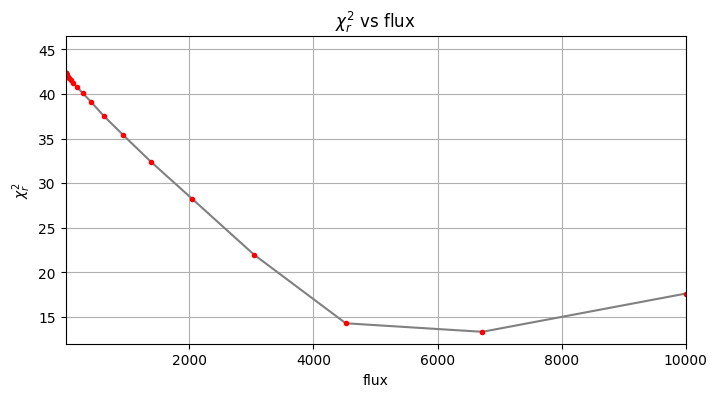

Planet 0: preliminary position guess: (r, theta)=(42.2, 242.3)
Planet 0: preliminary flux guess: 6723.4
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 125, nfev: 304, chi2r: 8.633439669479717
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(41.921, 241.488, 6688.022) at 
          (X,Y)=(79.99, 63.16)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:05:52.762131
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 10:28:45
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 379.414 GB
Done vectorizing the frames. Matrix shape: (288, 156025)
Done SVD/PC

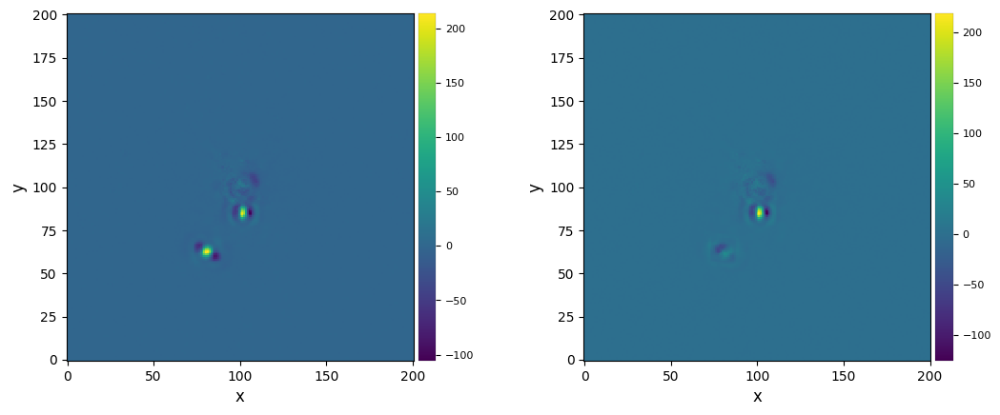

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 10:28:56
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 5.0607144853923405, # BRANCHES = 1, SIGMA = 5
Finished the throughput calculation
Running time:  0:10:37.477142
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


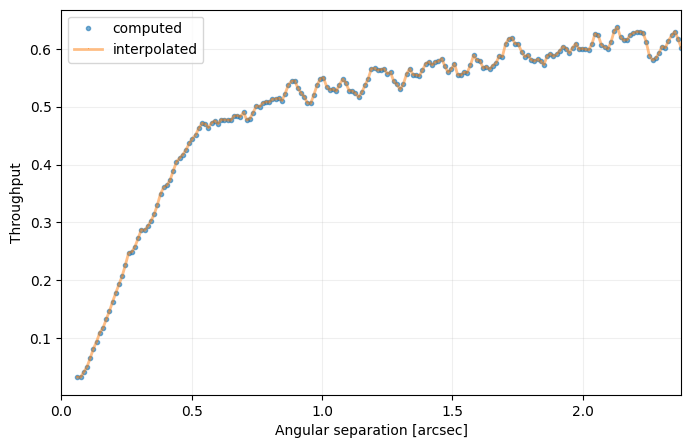

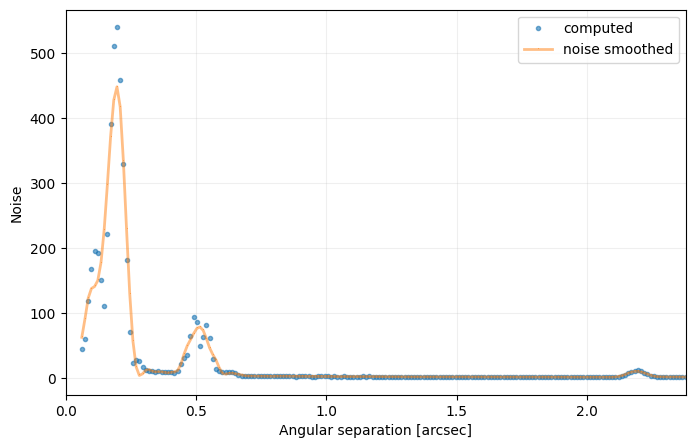

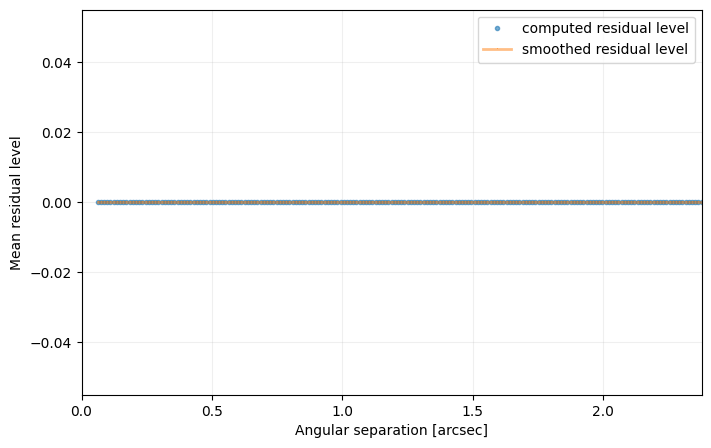

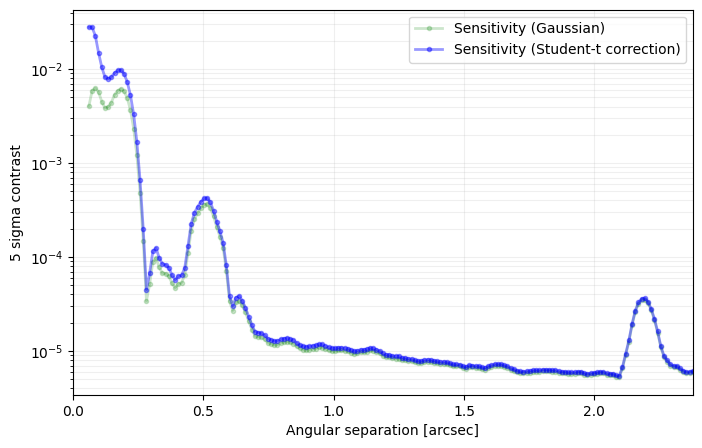

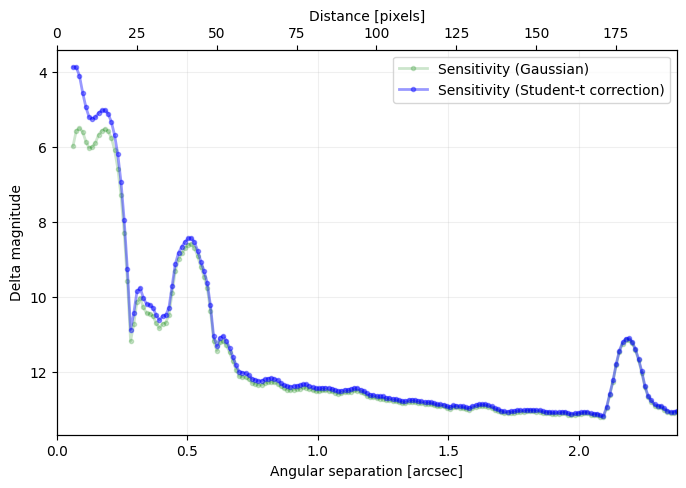

In [ ]:
angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/left_parallactic_angles.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/left_mastercube.fits')
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/FLUX_LEFT_CUT_OUT_SPHER.2023-03-31T00:50:05.345.fits')

print(cube.shape)

run_pca(cube, angs, flux)

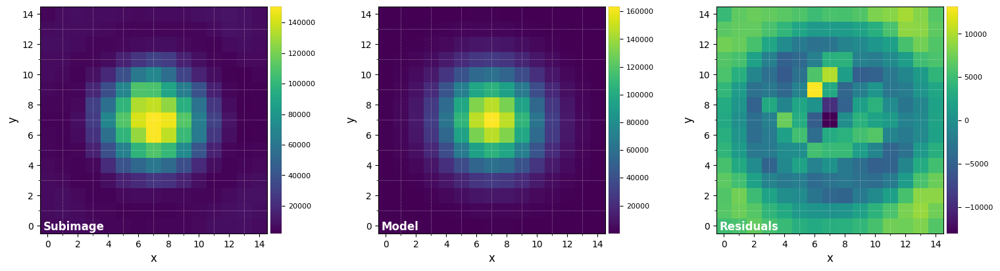

FWHM_y = 4.962046394211901
FWHM_x = 5.159382576572779 

centroid y = 6.999907983173395
centroid x = 7.000140103104112
centroid y subim = 6.999907983173395
centroid x subim = 7.000140103104112 

amplitude = 163501.31331301475
theta = -31.43357967644856

Mean FWHM: 5.061
Flux in 1xFWHM aperture: 2370410.576


In [ ]:
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/raw_files/FLUX_LEFT_CUT_OUT_SPHER.2023-03-31T00:50:05.345.fits')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/raw_files/left_mastercube.fits')

psfn, flux_count, fwhm_IRDIS = normalize_psf(flux, size=15, debug=True, full_output=True)

In [ ]:
np.nanmedian(cube)

-0.11520503613264077

In [ ]:

delta_mag = - 2.5 * np.log10(np.nansum(psfn) * 6688.022/ flux_count)

mag = 7.466 + delta_mag



parallax = 2.4262 * 10-3 #arcssec


d = 1/parallax #distance in pc
mu = 5*np.log10(d/10) #distance modulus
abs_mag = mag - mu



print(abs_mag, mag, delta_mag)


[24.63259039] [12.99456982] [5.52856982]


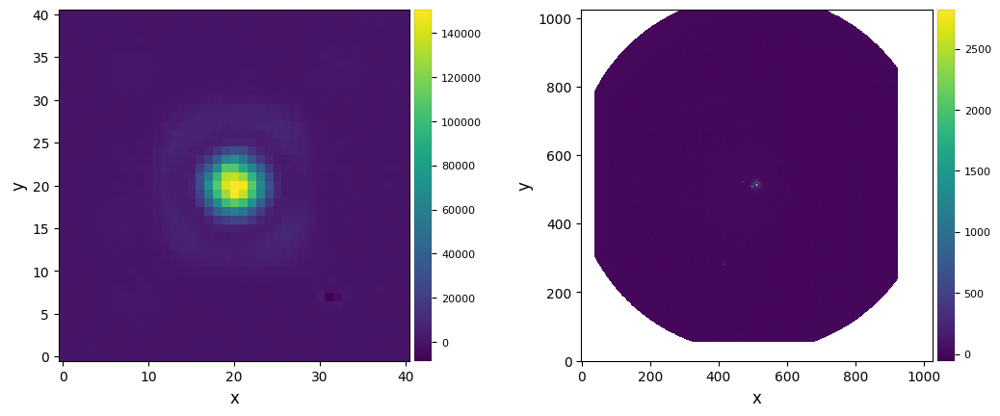

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 17:45:33
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 384.232 GB
Done vectorizing the frames. Matrix shape: (288, 1048576)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:45.566616
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:02:02.999481
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
New shape: (200, 200)


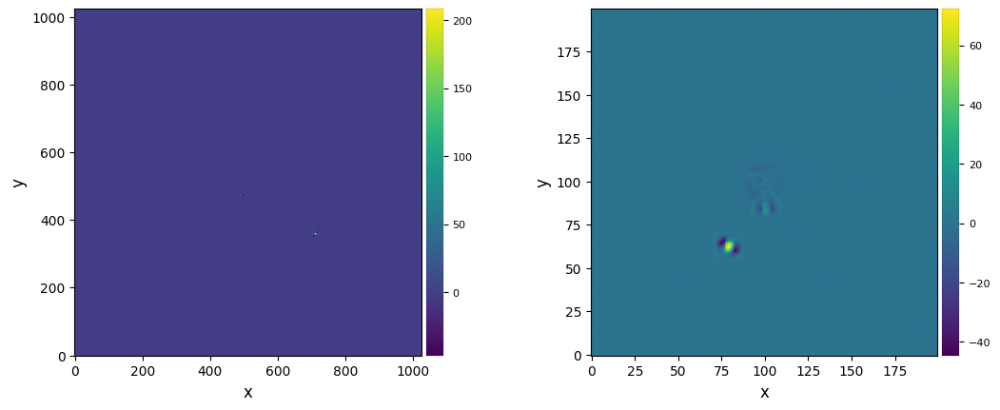

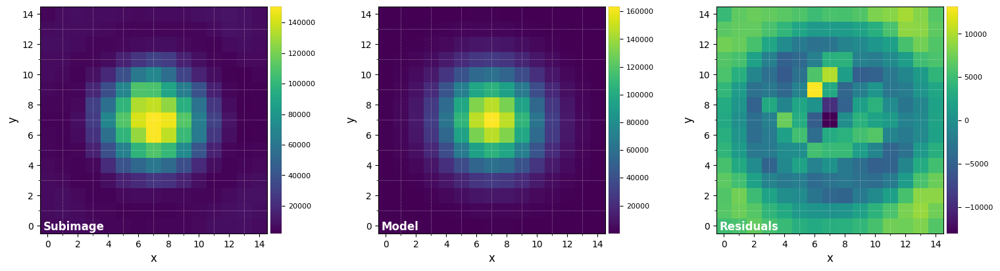

FWHM_y = 4.962046394211901
FWHM_x = 5.159382576572779 

centroid y = 6.999907983173395
centroid x = 7.000140103104112
centroid y subim = 6.999907983173395
centroid x subim = 7.000140103104112 

amplitude = 163501.31331301475
theta = -31.43357967644856

Mean FWHM: 5.061
Flux in 1xFWHM aperture: 2370410.576


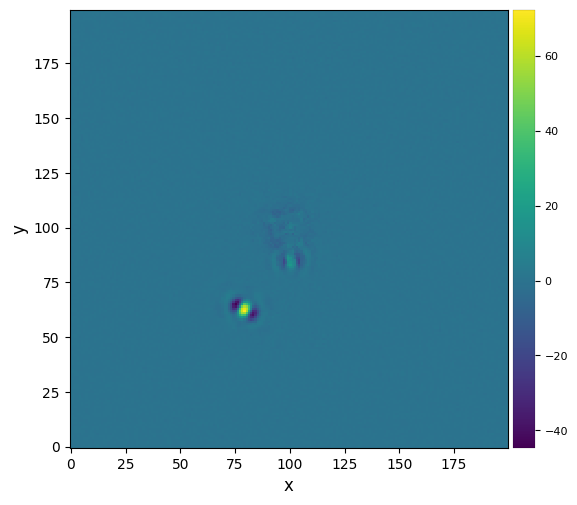

Blobs found: 1
 ycen   xcen
------ ------
62.507 	 78.892

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (78.9,62.5)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 78.9, 62.5
Flux in a centered 1xFWHM circular aperture = 950.446
Central pixel S/N = 13.068
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 14.389
Max S/N (shifting the aperture center) = 37.551
stddev S/N (shifting the aperture center) = 6.418

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


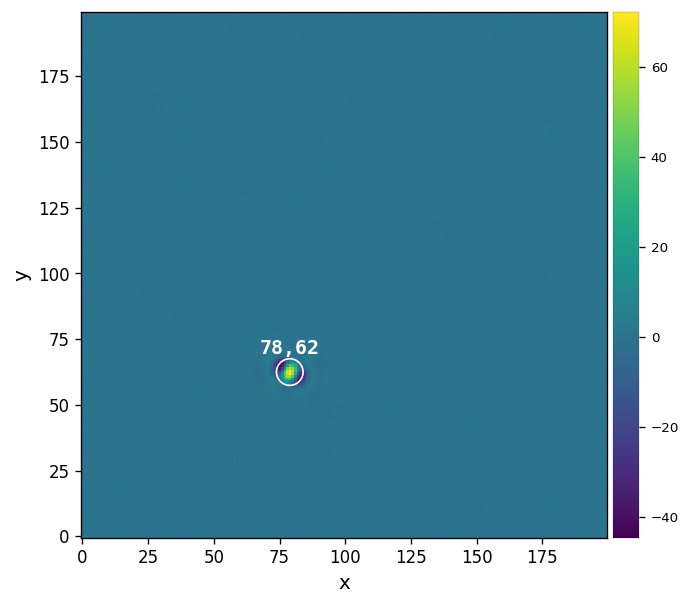

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 17:47:38
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [78.89157841389294,62.50670614573028], running ...
Step | flux    | chi2r
1/30   0.100   10.671
2/30   0.149   10.671
3/30   0.221   10.671
4/30   0.329   10.670
5/30   0.489   10.670
6/30   0.728   10.669
7/30   1.083   10.667
8/30   1.610   10.665
9/30   2.395   10.661
10/30   3.562   10.657
11/30   5.298   10.649
12/30   7.880   10.638
13/30   11.721   10.622
14/30   17.433   10.598
15/30   25.929   10.562
16/30   38.566   10.506
17/30   57.362   10.426
18/30   85.317   10.307
19/30   126.896   10.139
20/30   188.739   9.907
21/30   280.722   9.561
22/30 

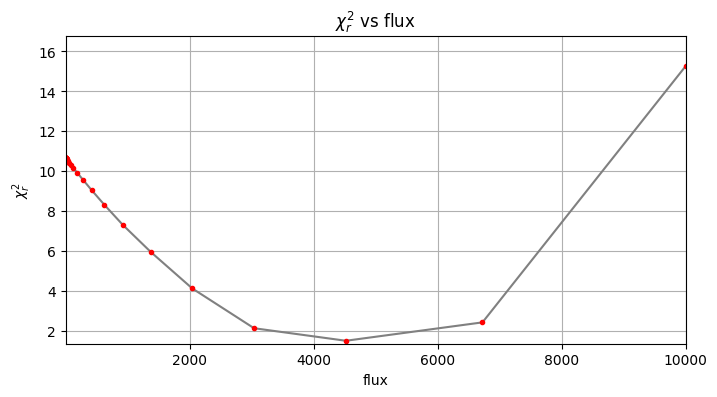

Planet 0: preliminary position guess: (r, theta)=(43.0, 240.6)
Planet 0: preliminary flux guess: 4520.4
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 103, nfev: 240, chi2r: 1.14526376989377
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(43.497, 240.839, 4545.263) at 
          (X,Y)=(78.81, 62.02)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:04:31.073704
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 17:52:12
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 383.669 GB
Done vectorizing the frames. Matrix shape: (288, 179776)
Done SVD/PCA

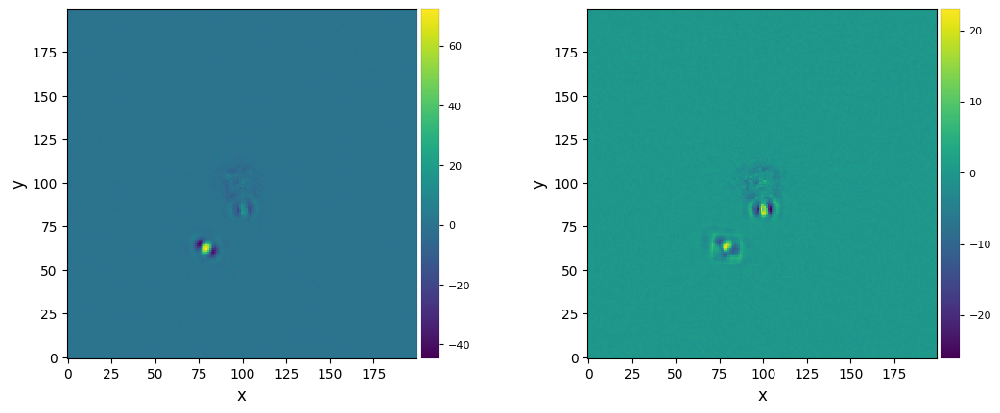

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-05 17:52:28
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 5.0607144853923405, # BRANCHES = 1, SIGMA = 5
Finished the throughput calculation
Running time:  0:12:09.206228
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


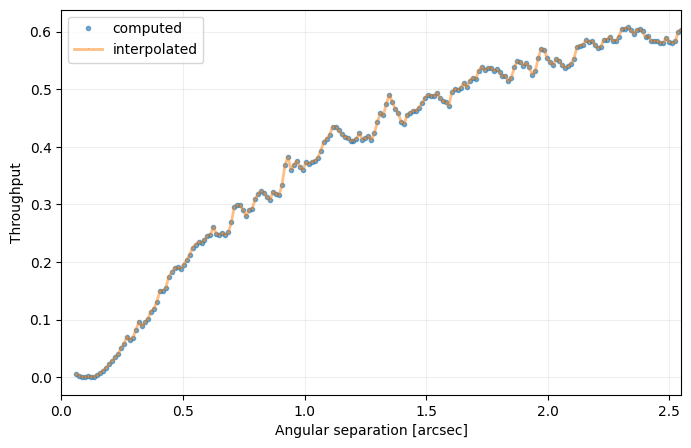

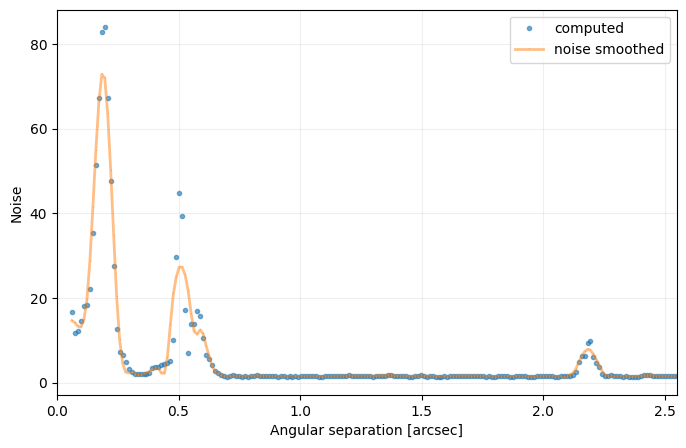

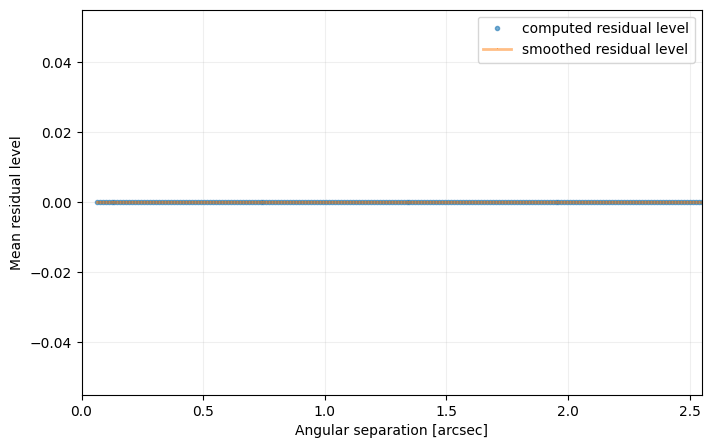

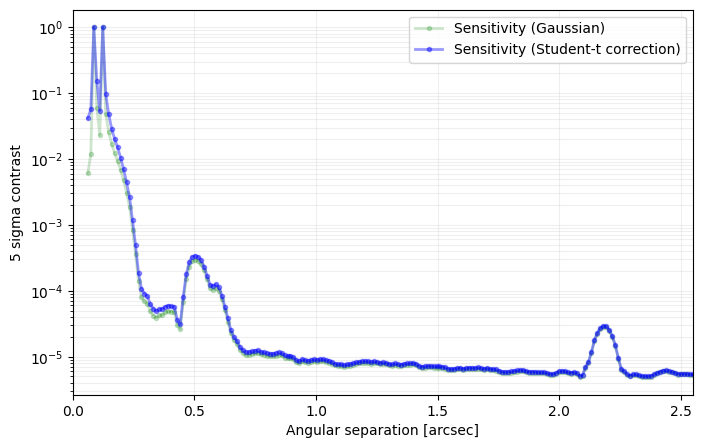

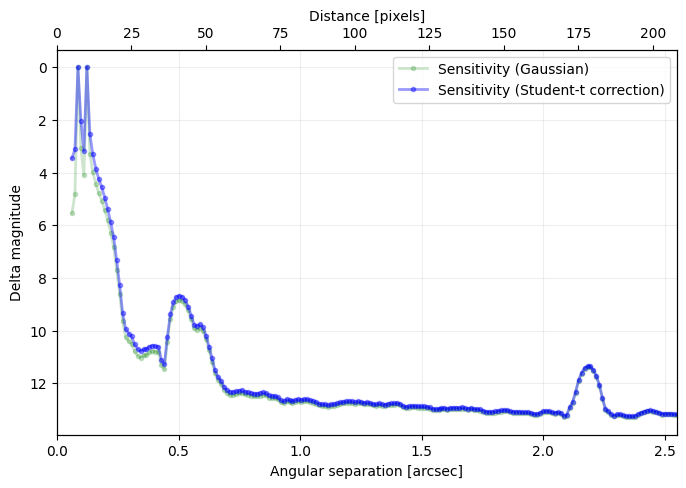

In [ ]:
angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_sphere_cubes/HD101412/IRDIS/2023-03-30/DB_K12/left/parallactic_angle.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_sphere_cubes/HD101412/IRDIS/2023-03-30/DB_K12/left/master_cube_PCA.fits')
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD101412/IRDIS/2023-03-30/DB_K12/left/raw_files/FLUX_LEFT_CUT_OUT_SPHER.2023-03-31T00:50:05.345.fits')


run_pca(cube, angs, flux)

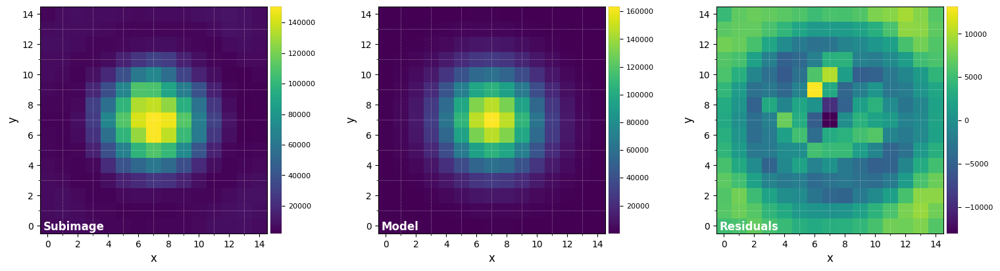

FWHM_y = 4.962046394211901
FWHM_x = 5.159382576572779 

centroid y = 6.999907983173395
centroid x = 7.000140103104112
centroid y subim = 6.999907983173395
centroid x subim = 7.000140103104112 

amplitude = 163501.31331301475
theta = -31.43357967644856

Mean FWHM: 5.061
Flux in 1xFWHM aperture: 2370410.576
[25.05193707] [13.4139165] [5.9479165]


In [ ]:
psfn, flux_count, fwhm_IRDIS = normalize_psf(flux, size=15, debug=True, full_output=True)

delta_mag = - 2.5 * np.log10(np.nansum(psfn) * 4545.263/ flux_count)

mag = 7.466 + delta_mag



parallax = 2.4262 * 10-3 #arcssec


d = 1/parallax #distance in pc
mu = 5*np.log10(d/10) #distance modulus
abs_mag = mag - mu



print(abs_mag, mag, delta_mag)

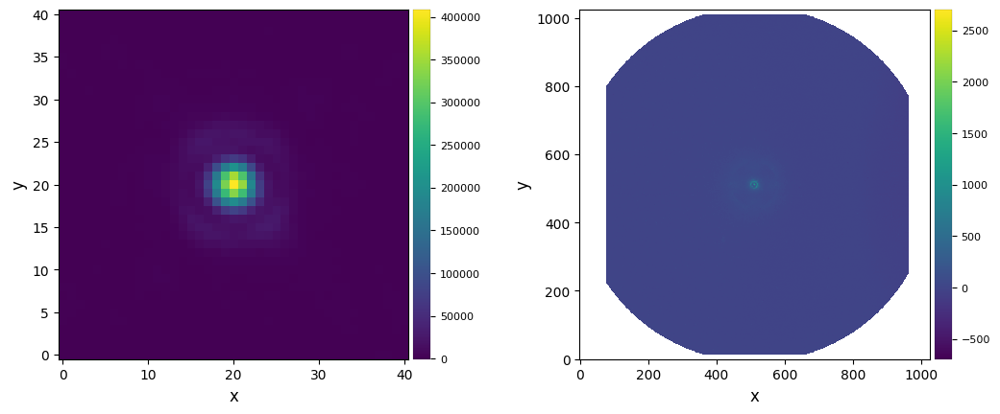

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-05-06 11:05:17
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.063 GB
System available memory = 381.550 GB
Done vectorizing the frames. Matrix shape: (480, 1050625)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:55.710120
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:01:54.689471
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


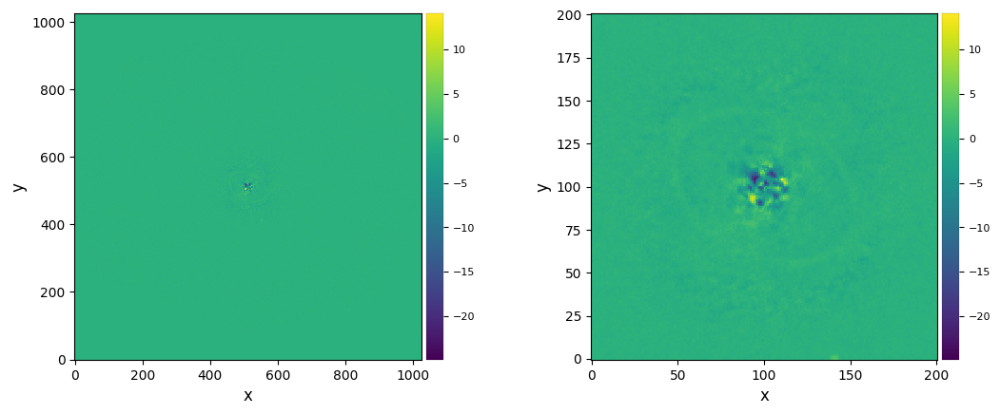

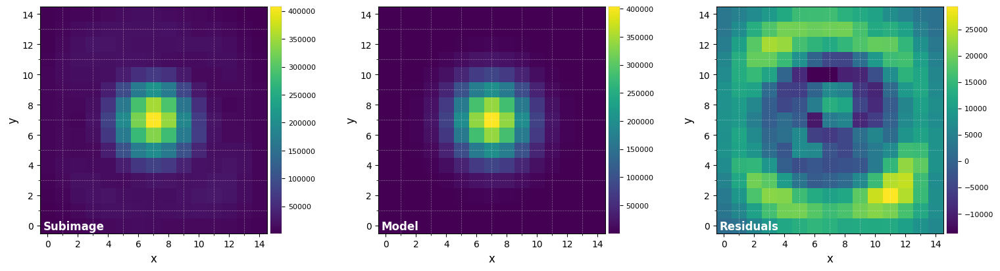

FWHM_y = 4.01271618093567
FWHM_x = 3.9076229646660368 

centroid y = 7.000061643158635
centroid x = 6.9999907626095474
centroid y subim = 7.000061643158635
centroid x subim = 6.9999907626095474 

amplitude = 403993.9753871396
theta = 24.52634681911402

Mean FWHM: 3.960
Flux in 1xFWHM aperture: 3505969.352


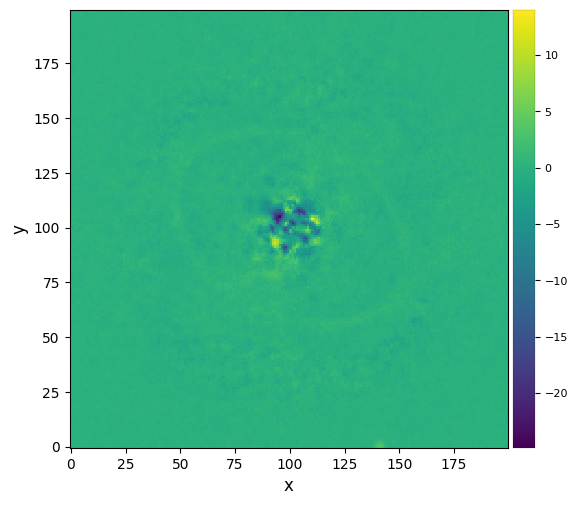

Blobs found: 1
 ycen   xcen
------ ------
0.744 	 140.632

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (140.6,0.7)
S/N constraint NOT fulfilled (S/N = nan)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


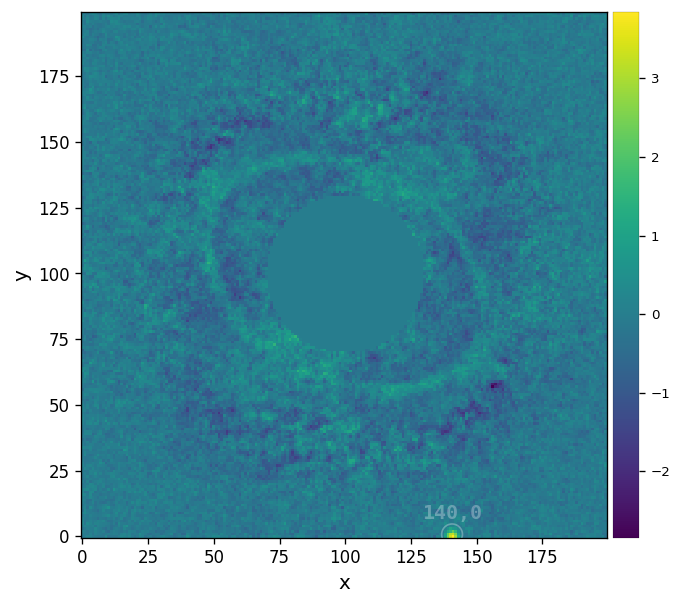

IndexError: index 0 is out of bounds for axis 0 with size 0

In [ ]:
angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD121617/IRDIS/2023-03-30/DB_H23/left/raw_files/left_parallactic_angles.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD121617/IRDIS/2023-03-30/DB_H23/left/raw_files/left_master_cube_PCA.fits')
flux = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/ispy_processed_data/HD121617/IRDIS/2023-03-30/DB_H23/left/raw_files/FLUX_LEFT_CUT_OUT_SPHER.2023-03-31T05:09:32.463.fits')

run_pca(cube, angs, flux)

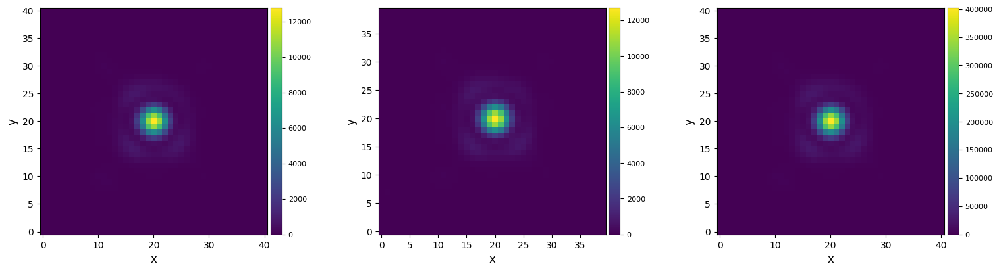

(299085.69981470087, 300313.6970886602, 177.92129673688333, 187.69606068041264)

In [ ]:
flux2 = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction/stage2/2FLUX_LEFT_CUT_OUT_SPHER.2023-07-24T09:55:27.364.fits')

fluxi = flux*0.126**2 *2
plot_frames([fluxi,flux_liz, flux2], vmin = 0)
np.sum(fluxi), np.sum(flux_liz), np.mean(fluxi), np.mean(flux_liz)

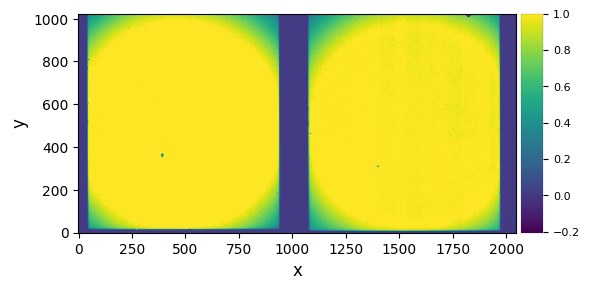

In [ ]:
masterflat = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction/stage1/MASTERFLAT.fits')

plot_frames(masterflat, vmax = 1)

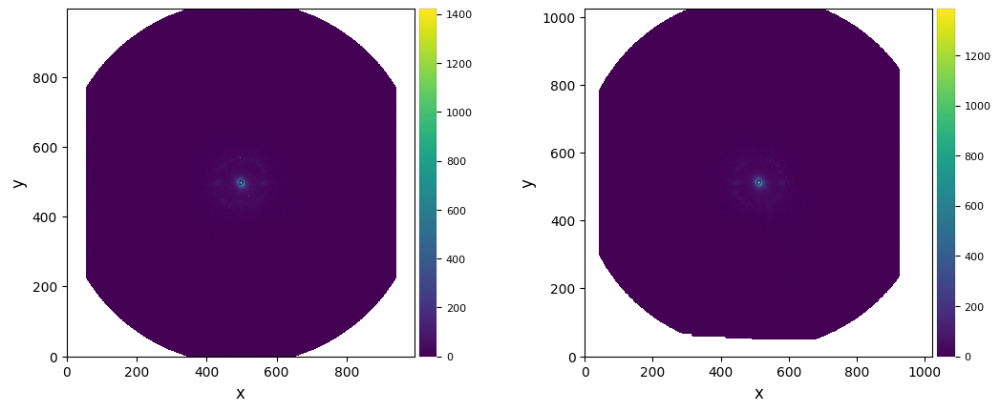

In [ ]:
plot_frames([cube[0],cube_liz[0]], vmin = 0)

In [ ]:
imlib = 'opencv'
imlib_rot = 'opencv' # other options: 'opencv', 'skimage'
interpolation= 'bilinear'  
pca_residual = pca(np.nan_to_num(cube[:,300:-300,300:-300]), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 10:54:44
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 1012.523 GB
Done vectorizing the frames. Matrix shape: (524, 156025)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:06.741635
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:00:18.156822
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


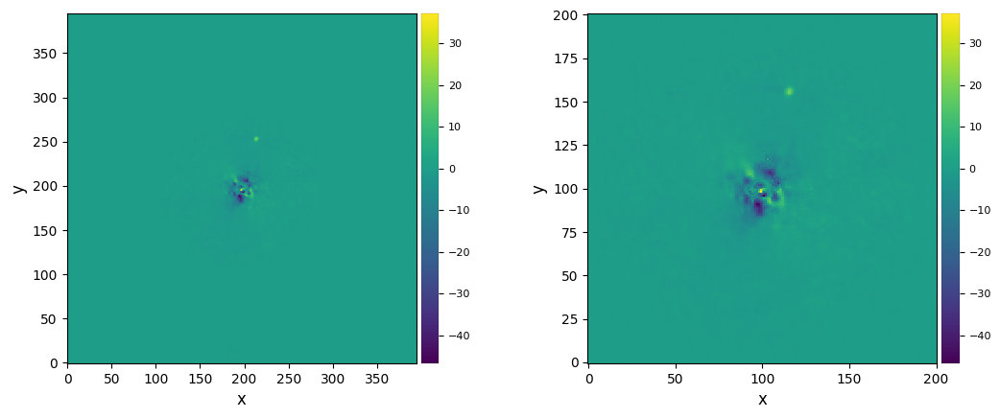

In [ ]:
cropped_residual = frame_crop(pca_residual, 200)

plot_frames([pca_residual, cropped_residual])

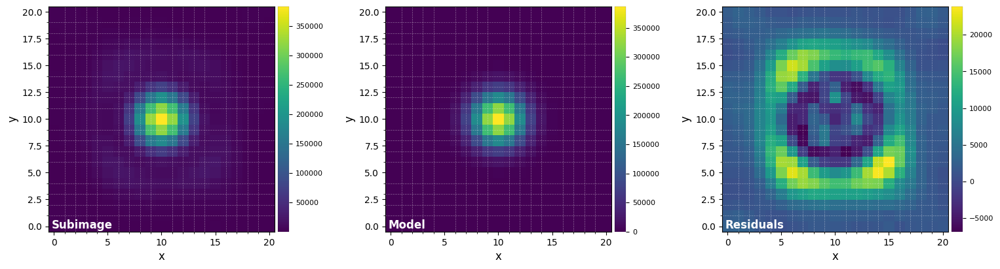

FWHM_y = 3.835914028178896
FWHM_x = 3.89873512324017 

centroid y = 9.9999821008145
centroid x = 10.000023505006052
centroid y subim = 9.9999821008145
centroid x subim = 10.000023505006052 

amplitude = 386826.0497350222
theta = -1.7251514403948367

Mean FWHM: 3.867
Flux in 1xFWHM aperture: 3201682.409


In [ ]:
psfn, flux, fwhm_IRDIS = normalize_psf(flux, size=21, debug=True, full_output=True)

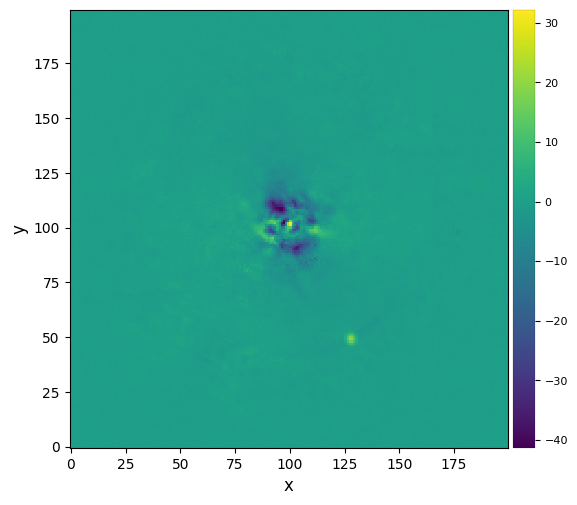

Blobs found: 1
 ycen   xcen
------ ------
49.218 	 127.488

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
X,Y = (127.5,49.2)
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Coords of chosen px (X,Y) = 127.5, 49.2
Flux in a centered 1xFWHM circular aperture = 170.259
Central pixel S/N = 21.053
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Inside a centered 1xFWHM circular aperture:
Mean S/N (shifting the aperture center) = 15.731
Max S/N (shifting the aperture center) = 20.054
stddev S/N (shifting the aperture center) = 3.344

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


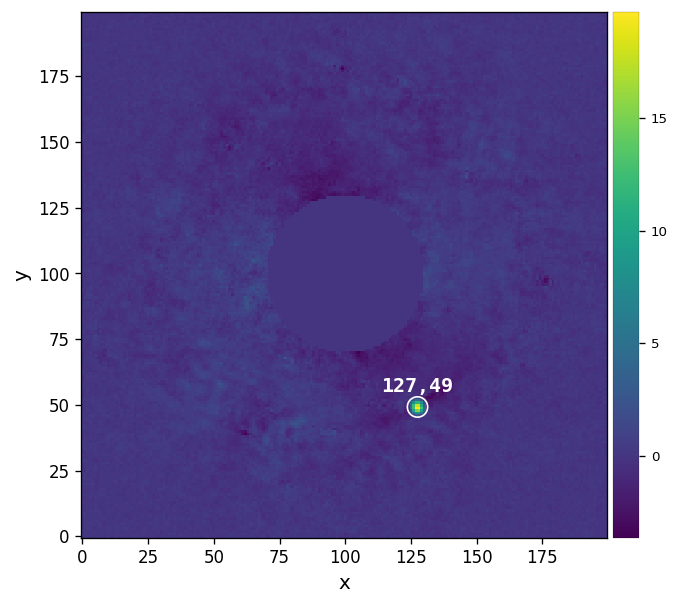

In [ ]:
from HCIutils import circular_aperture
from vip_hci.var import frame_center



cy,cx = frame_center(pca_residual)

central_mask = circular_aperture(pca_residual[cy-100:cy+100,cx-100:cx+100 ], 30, inverted = True)
plot_frames(pca_residual[cy-100:cy+100,cx-100:cx+100 ])

catalog = detection(pca_residual[cy-100:cy+100,cx-100:cx+100]*central_mask, fwhm=fwhm_IRDIS, psf=psfn, debug=False, mode='log', snr_thresh=5, bkg_sigma=5, matched_filter=False, mask = True)

In [ ]:
tuple(catalog)



(array([49.21845354]), array([127.48808643]))

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-28 17:18:47
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
             Planet 0           
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――

Planet 0: flux estimation at the position [127.48808643,49.21845354], running ...
Step | flux    | chi2r
1/30   0.100   9.004
2/30   0.149   9.001
3/30   0.221   8.996
4/30   0.329   8.988
5/30   0.489   8.977
6/30   0.728   8.960
7/30   1.083   8.935
8/30   1.610   8.899
9/30   2.395   8.847
10/30   3.562   8.769
11/30   5.298   8.654
12/30   7.880   8.484
13/30   11.721   8.220
14/30   17.433   7.871
15/30   25.929   7.346
16/30   38.566   6.599
17/30   57.362   5.564
18/30   85.317   4.227
19/30   126.896   2.536
20/30   188.739   0.841
21/30   280.722   0.138
22/30   417.532   2.940
23/30   621.

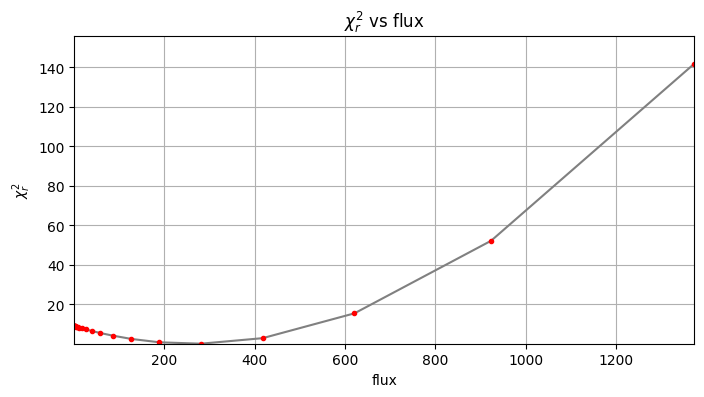

Planet 0: preliminary position guess: (r, theta)=(57.7, 298.4)
Planet 0: preliminary flux guess: 280.7
Planet 0: Simplex Nelder-Mead minimization, running ...
Planet 0: Success: True, nit: 91, nfev: 213, chi2r: 0.10947007970815041
message: Optimization terminated successfully.
Planet 0 simplex result: (r, theta, f)=(57.761, 298.452, 266.270) at 
          (X,Y)=(127.52, 49.22)

 ―――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――― 
DONE !
 ――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Running time:  0:38:20.190116
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


In [ ]:
cy,cx = frame_center(cube[0])

xy_test = (127.48808643, 49.21845354)

r_lo, theta_lo, f_lo = firstguess(cube[:,cy-100:cy+100,cx-100:cx+100], angs, psfn, ncomp=5, planets_xy_coord=[xy_test], 
                            fwhm=fwhm_IRDIS, f_range=None, annulus_width=4*fwhm_IRDIS, 
                            aperture_radius=2, simplex=True, imlib=imlib_rot, 
                            interpolation=interpolation, plot=True, verbose=True)



In [ ]:

#plpar_fc = (r_lo[0], theta_lo[0], f_lo[0])
plpar_fc = (57.761, 298.452 + 135.99, 266.270)
cube_emp = cube_planet_free(plpar_fc, cube, angs, psfn, imlib=imlib_rot, interpolation=interpolation)


imlib = 'opencv'
imlib_rot = 'opencv' # other options: 'opencv', 'skimage'
interpolation= 'bilinear'  
pca_residual_free = pca(np.nan_to_num(cube_emp[:,300:-300,300:-300]), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 10:56:16
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.061 GB
System available memory = 997.276 GB
Done vectorizing the frames. Matrix shape: (524, 156025)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:00:06.298550
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:00:18.616742
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


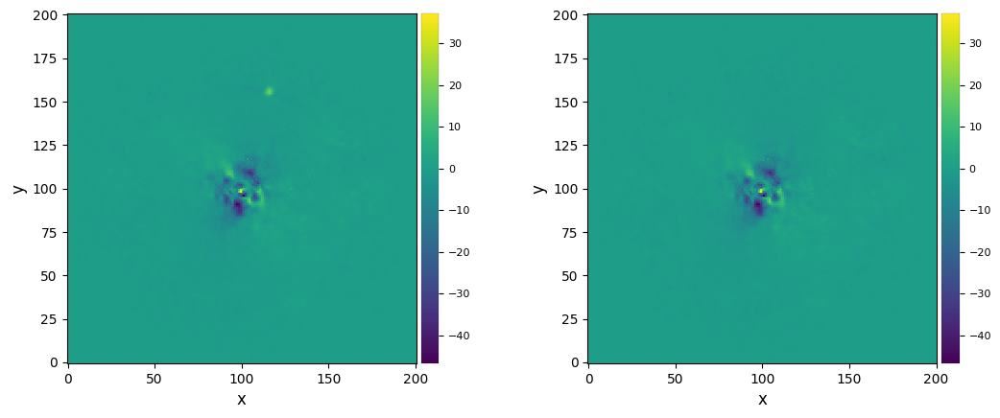

In [ ]:
cropped_residual_free = frame_crop(pca_residual_free, 200)

plot_frames([cropped_residual, cropped_residual_free])

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-29 11:21:06
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
ALGO : pca, FWHM = 3.867324575709533, # BRANCHES = 1, SIGMA = 5
Finished the throughput calculation
Running time:  0:02:32.372135
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


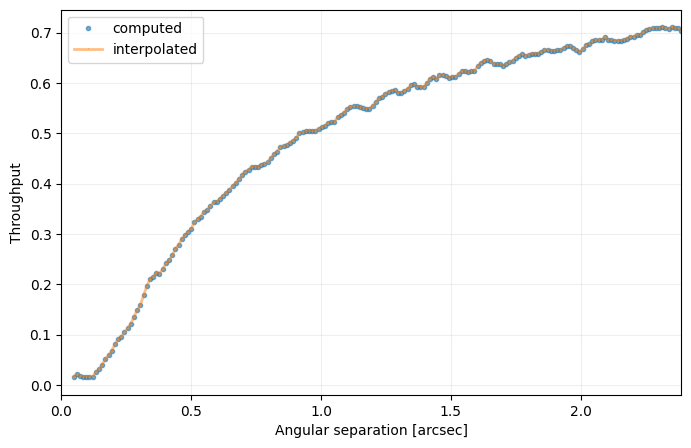

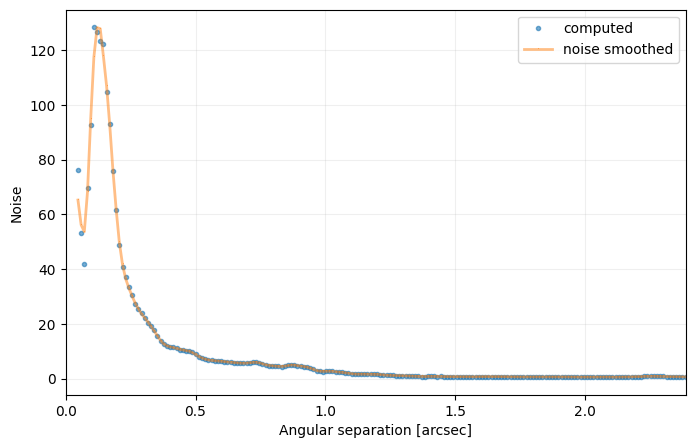

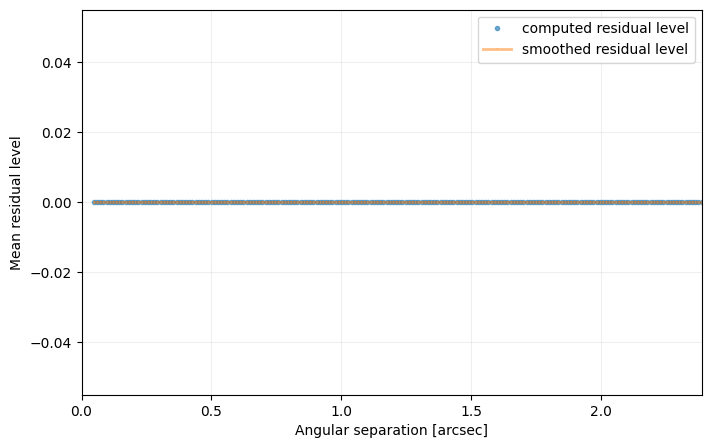

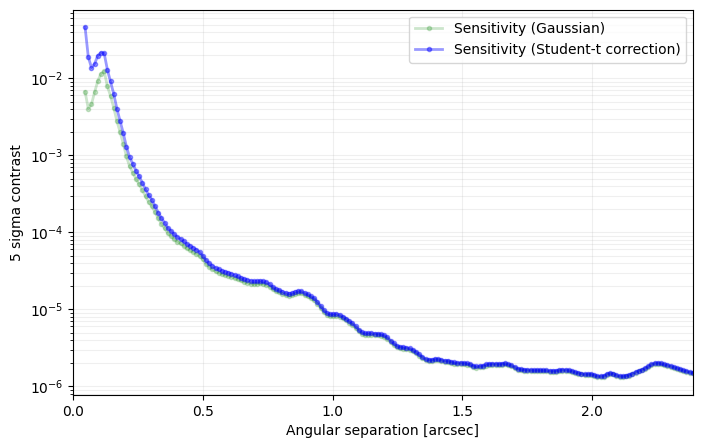

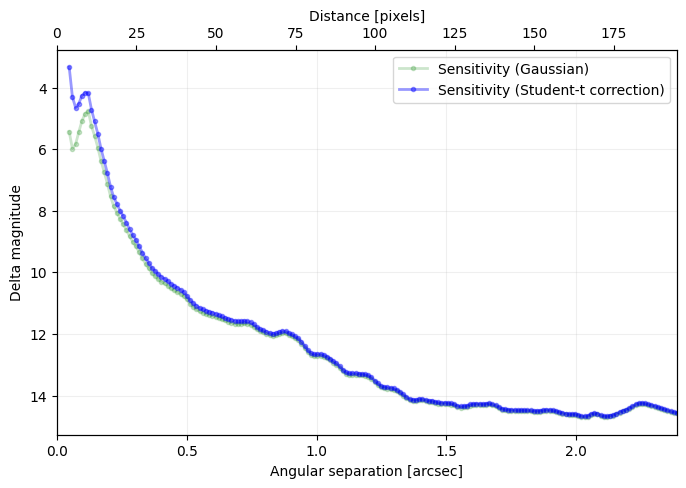

In [ ]:
from vip_hci.config import VLT_SPHERE_IRDIS

pxscale = VLT_SPHERE_IRDIS['plsc']
starphot = flux
cc_1 = contrast_curve(cube_emp[:,300:-300,300:-300], angs, psfn, fwhm=fwhm_IRDIS, pxscale=pxscale, starphot=starphot,
                       sigma=5, nbranch=1, algo=pca, ncomp=5, debug=True, svd_mode='pytorch', verbose=True, interpolation ='bilinear', imlib='opencv')

In [ ]:
imlib = 'opencv' # other options: 'opencv', 'skimage'
interpolation= 'bilinear'  
pca_residual = pca(np.nan_to_num(cube), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-25 13:09:45
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.561 GB
System available memory = 262.088 GB
Done vectorizing the frames. Matrix shape: (524, 880575)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:02:52.498792
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:03:59.009871
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)


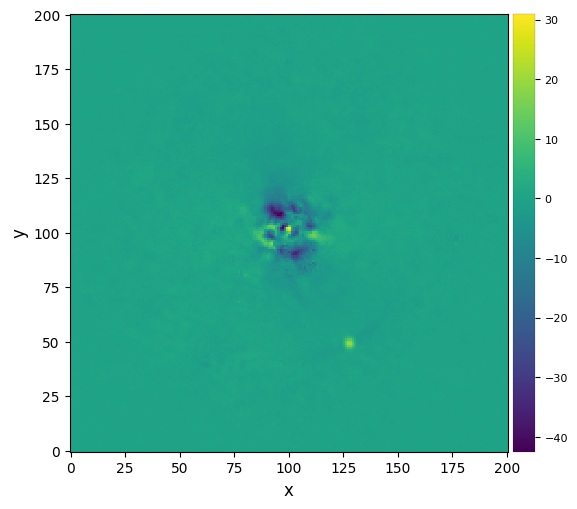

In [ ]:
crop = frame_crop(pca_residual, 200)
plot_frames(crop)

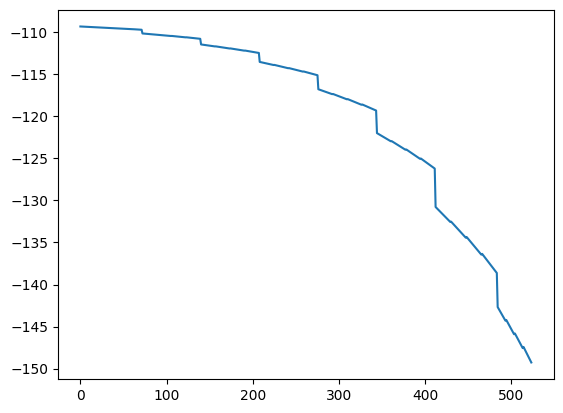

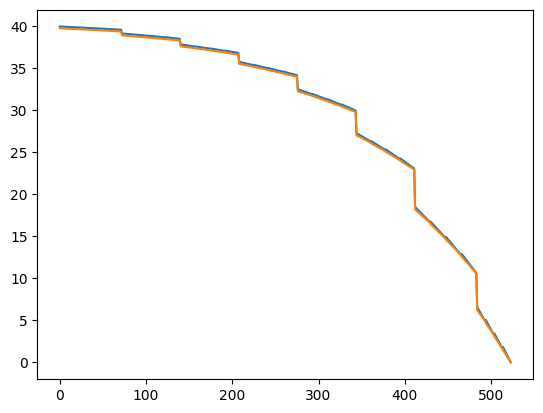

In [ ]:
parangs = np.loadtxt('/home/pasteimle/code/ispy/Notebooks/hd11397_20230723_left_parang.txt')

parangs2 = (parangs + 100) % 360 - 100
parangs2 = parangs2 - np.min(parangs2)

angs2 = angs - np.min(angs)

plt.plot(angs2)
plt.plot(parangs2)

array([2.66593060e+01, 2.66541520e+01, 2.66489980e+01, 2.66438450e+01,
       2.66386910e+01, 2.66335380e+01, 2.66283840e+01, 2.66232300e+01,
       2.66180770e+01, 2.66129230e+01, 2.66077700e+01, 2.66026160e+01,
       2.65974620e+01, 2.65923090e+01, 2.65871550e+01, 2.65820020e+01,
       2.65768480e+01, 2.65716940e+01, 2.65725000e+01, 2.65669120e+01,
       2.65613240e+01, 2.65557350e+01, 2.65501470e+01, 2.65445590e+01,
       2.65389710e+01, 2.65333820e+01, 2.65277940e+01, 2.65222060e+01,
       2.65166180e+01, 2.65110290e+01, 2.65054410e+01, 2.64998530e+01,
       2.64942650e+01, 2.64886760e+01, 2.64830880e+01, 2.64775000e+01,
       2.64816940e+01, 2.64756720e+01, 2.64696490e+01, 2.64636260e+01,
       2.64576030e+01, 2.64515800e+01, 2.64455570e+01, 2.64395340e+01,
       2.64335110e+01, 2.64274890e+01, 2.64214660e+01, 2.64154430e+01,
       2.64094200e+01, 2.64033970e+01, 2.63973740e+01, 2.63913510e+01,
       2.63853280e+01, 2.63793060e+01, 2.63819440e+01, 2.63753630e+01,
      

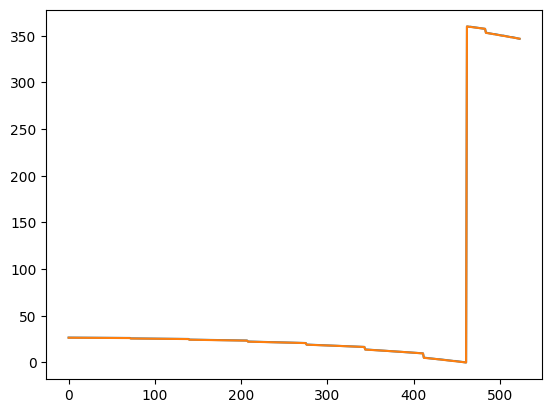

In [ ]:
plt.plot((angs + 135.99 ) % 360)
plt.plot(parangs)

Text(0.5, 0, '# frame')

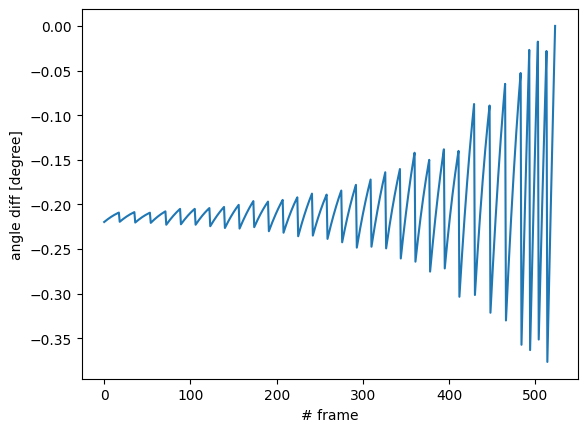

In [ ]:
plt.plot(-(angs2-parangs2))
plt.ylabel('angle diff [degree]')
plt.xlabel('# frame')



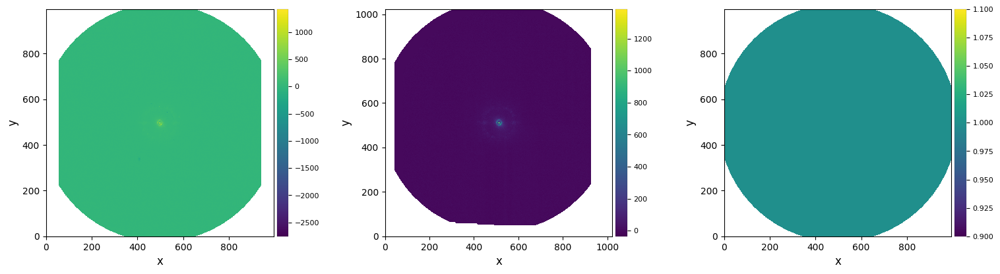

In [ ]:
angs_liz = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_right_parang.txt')
cube_liz = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397_reduced/hd11397_20230723_left_scicube.fits')

angs = np.loadtxt('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/hd11397_final_data_new/LEFT_angs.txt')
cube = fits.getdata('/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/hd11397_final_data_new/LEFT_CUBE_BADPIX_CORR.fits')

from HCIutils import circular_aperture

data = cube

#find longest side
long_side = int(np.max(data[0].shape))
short_side = int(np.min(data[0].shape))



nan_cube = np.zeros((len(data), long_side, long_side)) * np.nan
diff = int((long_side-short_side)/2)

if data.shape[1] == long_side:
    nan_cube[:,:,diff:-diff] = data

elif data.shape[2] == long_side:
    nan_cube[:,diff:-diff,:] = data

mask = circular_aperture(nan_cube[0], 520, inverted=False)
mask[mask == 0] = np.nan

plot_frames([nan_cube[0]*mask,cube_liz[0], mask])

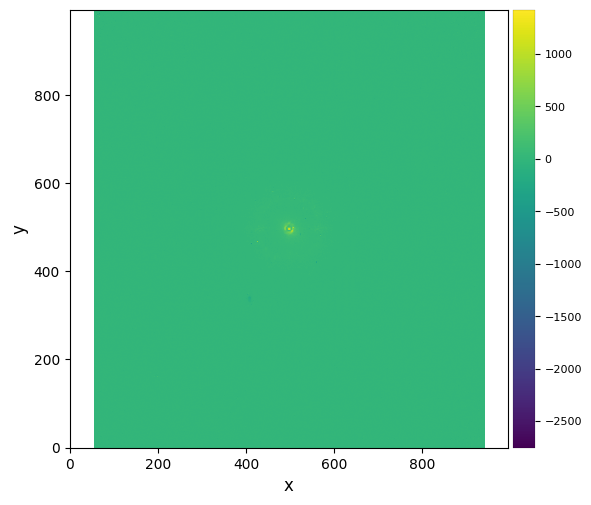

In [ ]:
plot_frames(nan_cube[0])


In [ ]:
imlib = 'opencv'
interpolation= 'bilinear'  
pca_residual_elisabeth= pca(np.nan_to_num(cube), angs, ncomp = 5 , imlib=imlib, interpolation=interpolation, nproc = 30)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Starting time: 2025-04-25 15:58:06
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
System total memory = 1081.561 GB
System available memory = 276.421 GB
Done vectorizing the frames. Matrix shape: (524, 1048576)
Done SVD/PCA with numpy SVD (LAPACK)
Running time:  0:04:51.131766
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Done de-rotating and combining
Running time:  0:07:06.691290
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


`Size` is even (while input frame size is odd). Setting `size` to 201 pixels
New shape: (201, 201)
New shape: (200, 200)


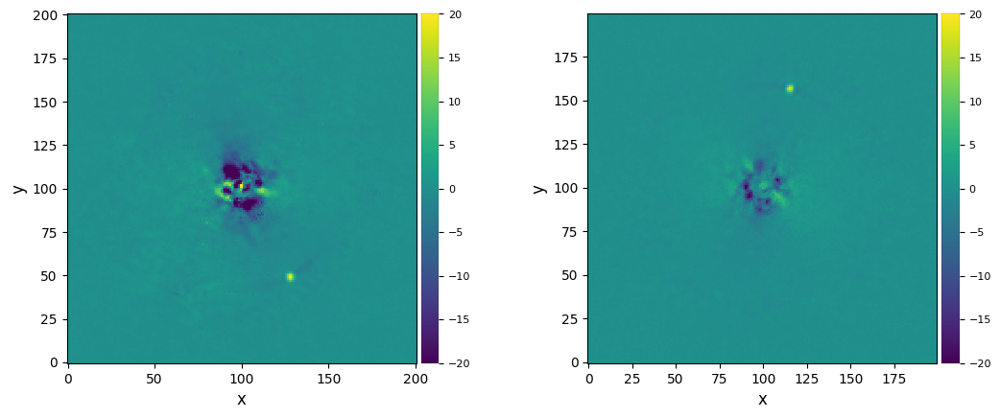

In [ ]:
crop = frame_crop(pca_residual, 200)
crop_elisabeth = frame_crop(pca_residual_elisabeth, 200)
plot_frames([crop, crop_elisabeth], vmin = -20, vmax = 20)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
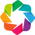

:Layout
   .Image.I  :Image   [x,y]   (z)
   .Image.II :Image   [x,y]   (z)

In [ ]:
plot_frames([pca_residual, pca_residual_elisabeth], vmin = -20, vmax = 20, backend='bokeh')

`Size` is even (while input frame size is odd). Setting `size` to 21 pixels
New shape: (21, 21)
New shape: (20, 20)


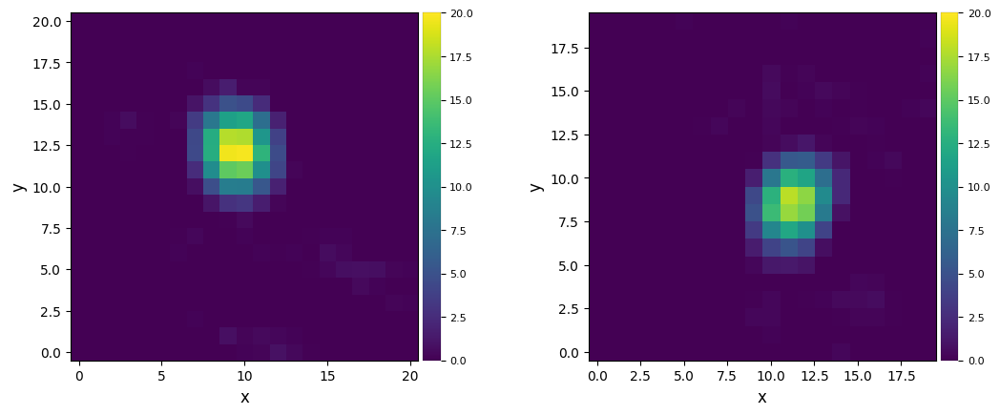

In [ ]:
crop = frame_crop(pca_residual, 20, xy = (470,444))
crop_elisabeth = frame_crop(pca_residual_elisabeth, 20, xy = (526, 570))
plot_frames([crop, crop_elisabeth], vmax = 20, vmin = 0)

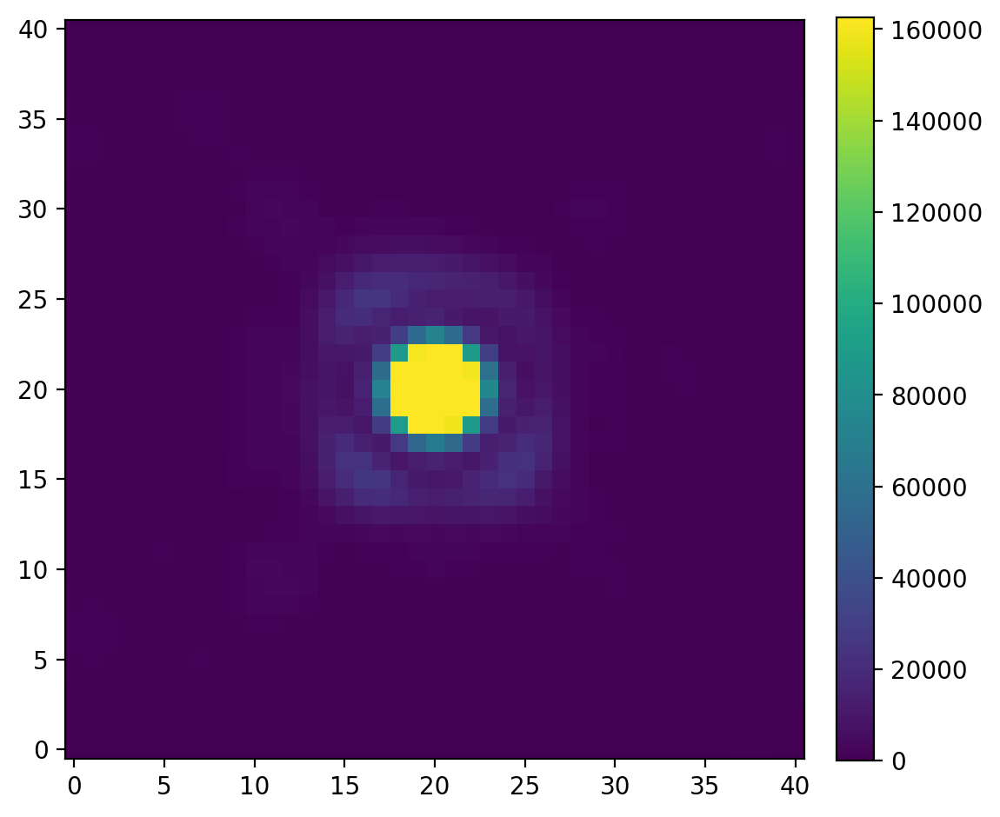

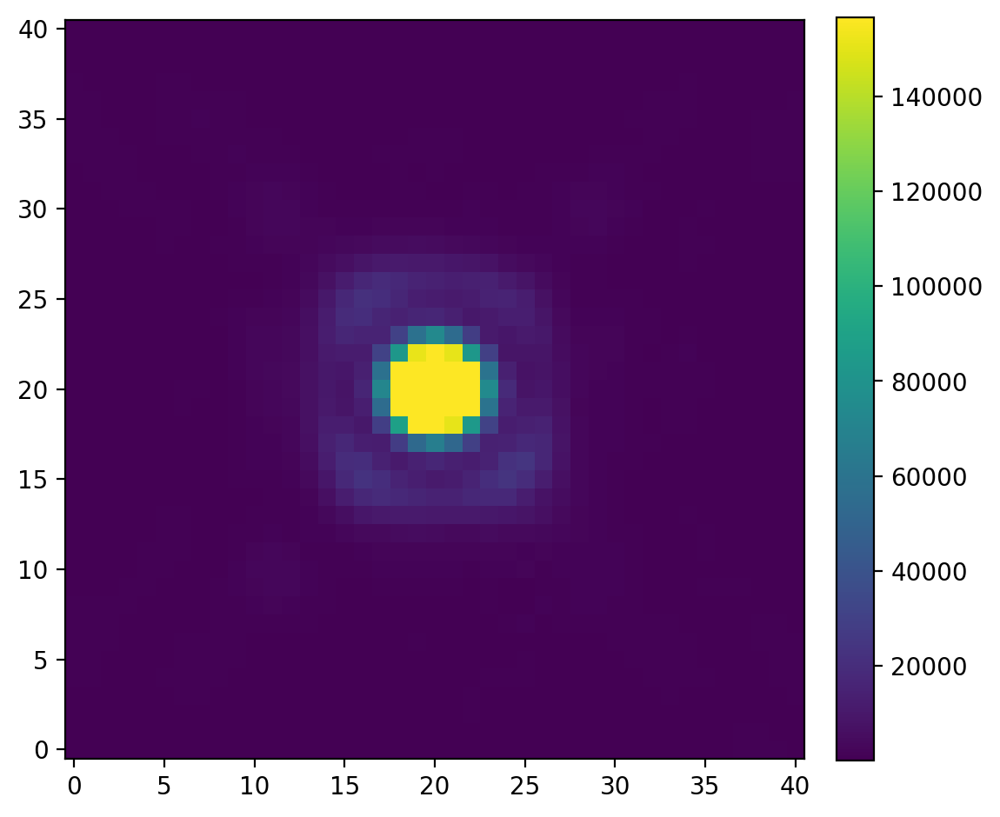

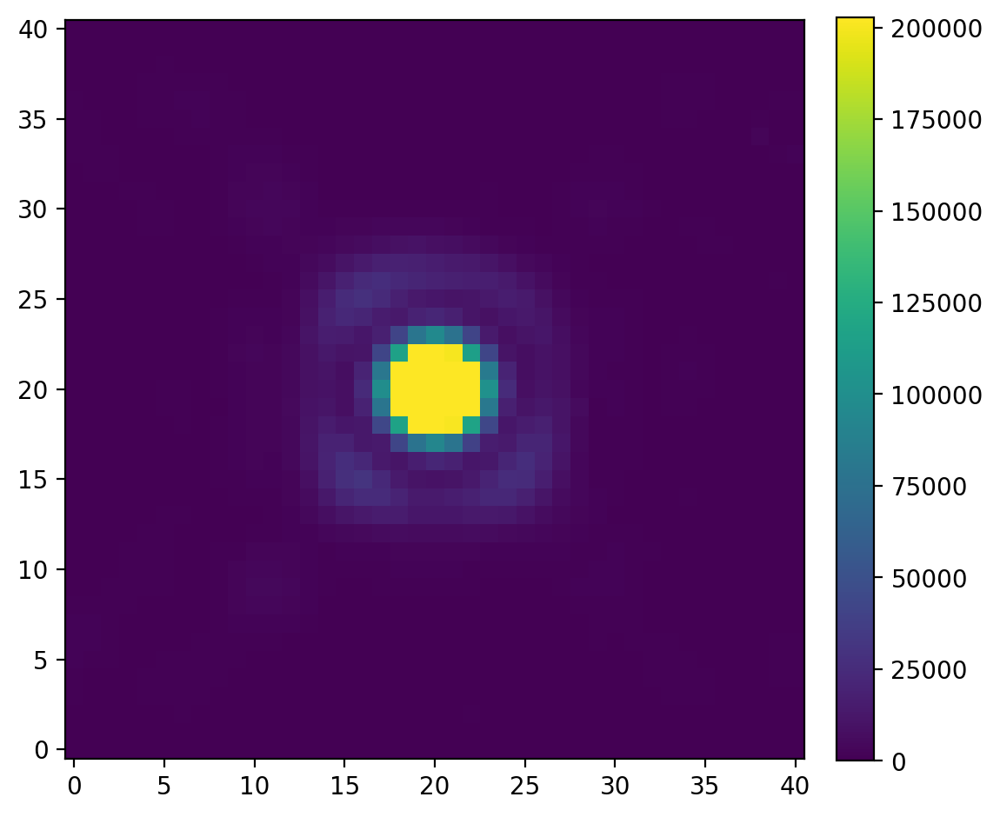

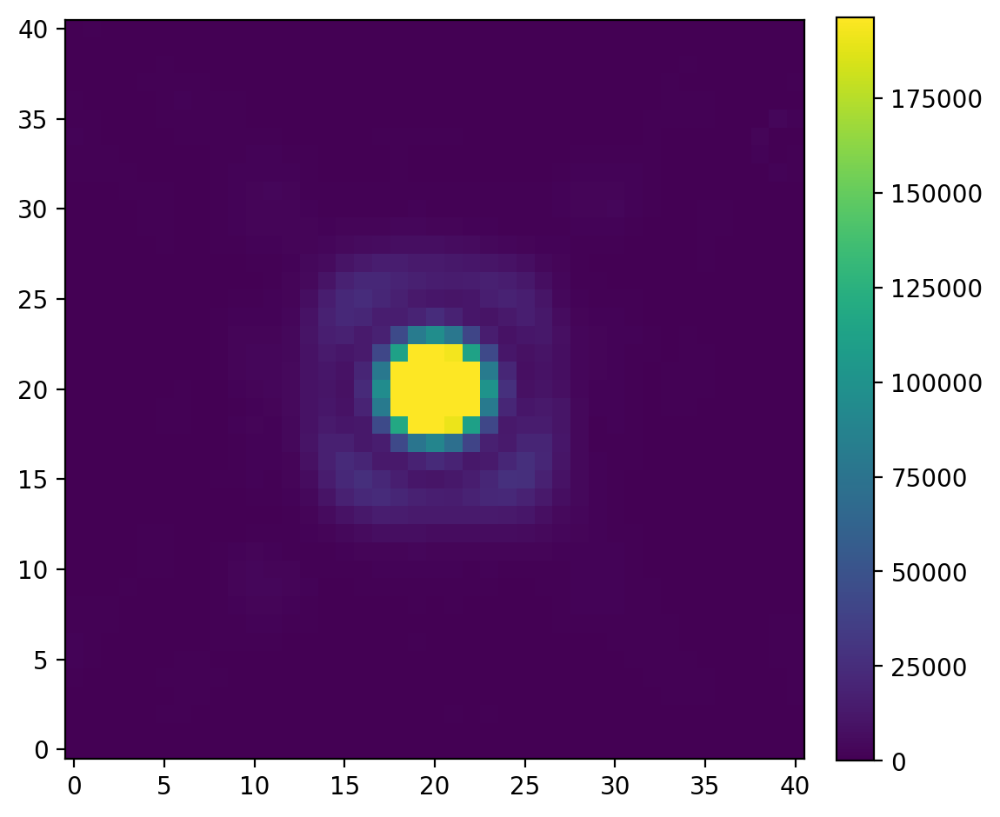

In [ ]:
from HCIutils import show_img
for L_or_R in ['LEFT', 'RIGHT']:
    for path in glob(f'/data/beegfs/astro-storage/groups/beuther/pasteimle/HD11397/test_reduction/stage1/FLUX_{L_or_R}_CUT_OUT_SPHER.*fits'):
        show_img(fits.getdata(path))